# Actividad 2 — Regresión lineal y regularizada

**Técnicas de Análisis Estadístico de Modelos Supervisados**
**Datos:** base depurada de la Actividad 1 (*Mice Protein Expression*, 1.077 réplicas de 72 ratones).

**Objetivo del notebook:** construir, diagnosticar y comparar modelos de regresión lineal múltiple y regularizada
para `pERK_N`, validados por ratón.

| Sección | Contenido |
|---|---|
| 0 | Preparación del entorno |
| 1 | Planteamiento del problema |
| 2 | Partición por ratón y línea base |
| 3 | Regresión lineal múltiple inferencial (M1) |
| 4 | Supuestos, multicolinealidad e influencia |
| 5 | Modelos regularizados (M2) |
| 6 | Validación cruzada y comparación |
| 7 | Estabilidad de coeficientes, modelo final y prueba |
| 8 | Conclusiones y limitaciones |

## 0. Preparación del entorno

In [1]:
# Librerías externas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

from sklearn.model_selection import StratifiedGroupKFold, GroupKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer 
from sklearn.impute import KNNImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error, mean_absolute_error

# Paquete del proyecto: semilla, rutas y funciones de carga
from mice_supervisado.config import SEMILLA, ruta_figuras
from mice_supervisado.datos import cargar_depurados

# Configuración de la sesión
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 90)
FIGURAS = ruta_figuras(2)

In [2]:
# Variables del análisis (se usan en todo el notebook)
OBJETIVO = "pERK_N"
PREDICTORES_M1 = ["DYRK1A_N", "BRAF_N", "ITSN1_N"]
DISENO = ["Genotype", "Treatment", "Behavior"]
GRUPO = "raton"

df = cargar_depurados()
PROTEINAS_M2 = [col for col in df.columns if col.endswith("_N") and col != OBJETIVO]

# Verificaciones de la base depurada (Actividad 1, sección 6)
assert df.shape == (1077, 83)
assert len(PROTEINAS_M2) == 75
assert all(df[col].dtype == "category" for col in DISENO)
assert df[[OBJETIVO] + PREDICTORES_M1 + DISENO].isna().sum().sum() == 0

print(f"Base: {df.shape} | ratones: {df[GRUPO].nunique()} | proteínas para M2: {len(PROTEINAS_M2)}")

Base: (1077, 83) | ratones: 72 | proteínas para M2: 75


In [3]:
# Faltantes que quedan para M2; se imputan con KNN dentro del Pipeline (sección 5)
faltantes_m2 = df[PROTEINAS_M2].isna().sum()
faltantes_m2[faltantes_m2 > 0].sort_values(ascending=False)

BCL2_N        285
H3MeK4_N      270
BAD_N         213
EGR1_N        210
H3AcK18_N     180
pCFOS_N        75
Bcatenin_N     15
ELK_N          15
MEK_N           4
RRP1_N          1
dtype: int64

## 1. Planteamiento del problema

Para el desarrollo del modelo lineal se seleccionó `pERK_N` como variable objetivo, ya que corresponde a la forma
fosforilada, es decir, activa, de ERK y constituye el punto final de la cascada MAPK. Esta vía está implicada en
la plasticidad sináptica y la memoria (Sweatt, 2004), que es precisamente el foco del experimento, en el que ratones
control y Ts65Dn, modelo murino del síndrome de Down, fueron estimulados o no para aprender (Higuera et al.,
2015). Además, DYRK1A potencia
la activación de ERK dentro de esta cascada (Kelly & Rahmani, 2005), de modo que `pERK_N` tiene sentido como
variable respuesta y sus predictores cuentan con una explicación biológica.

Por otra parte, los predictores tienen razones estadísticas sólidas: `pERK_N` se correlaciona fuertemente con
`DYRK1A_N` (ρ = 0,93), `BRAF_N` (ρ = 0,86) e `ITSN1_N` (ρ = 0,83), y estas correlaciones se mantienen al calcularlas
con promedios por ratón (sección 5.2 de la Actividad 1). En consecuencia, se plantean dos modelos: uno interpretable
(M1), con estas tres proteínas y las variables de diseño, para estimar cuánto se asocia cada una con `pERK_N`; y
uno amplio (M2), con las 75 proteínas restantes, para evaluar si la regularización mejora la predicción. En ambos
casos, la unidad de análisis es el ratón, por lo que la validación se agrupa por individuo.

### 1.1 Distribución de la variable objetivo

¿La transformación logarítmica corrige la asimetría de `pERK_N` observada en la sección 2.2 de la Actividad 1?

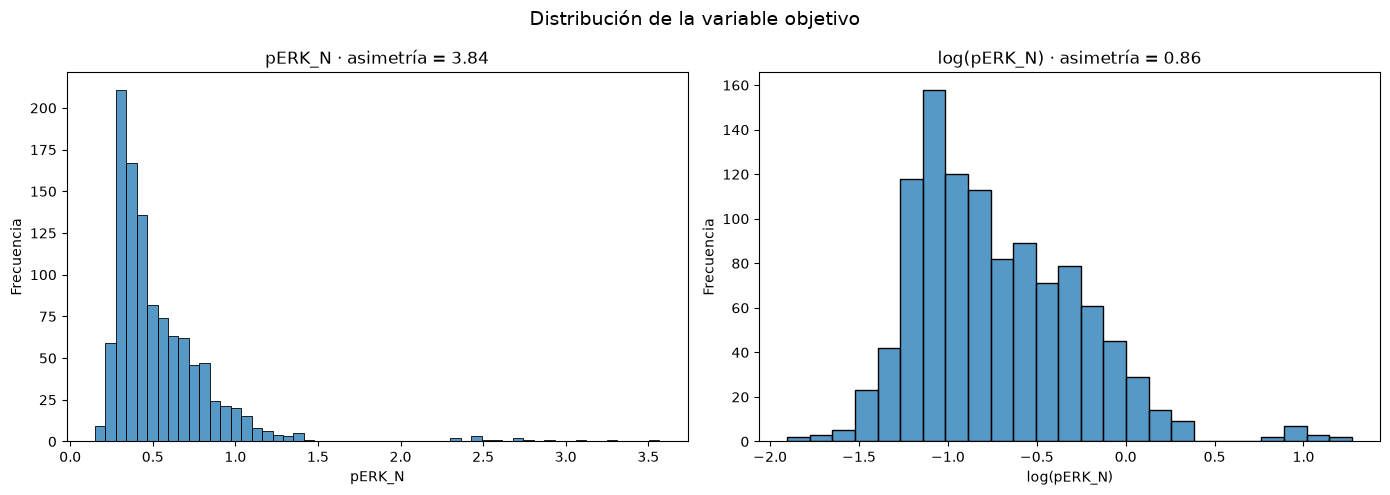

Asimetría de log(pERK_N) sin el ratón 3484: 0.39


In [4]:
versiones = {
    "pERK_N": df[OBJETIVO],
    "log(pERK_N)": np.log(df[OBJETIVO]),
}

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, (nombre, valores) in zip(axs, versiones.items()):
    sns.histplot(valores, ax=ax)
    ax.set(title=f"{nombre} · asimetría = {valores.skew():.2f}", xlabel=nombre, ylabel="Frecuencia")

fig.suptitle("Distribución de la variable objetivo", fontsize=14)
fig.tight_layout()
plt.savefig(FIGURAS / "perk_histograma.png", dpi=150, bbox_inches="tight")
plt.show()

# Asimetría en escala log sin el ratón con valores extremos (Actividad 1, sección 4)
sin_3484 = df[df[GRUPO] != "3484"]
print(f"Asimetría de log(pERK_N) sin el ratón 3484: {np.log(sin_3484[OBJETIVO]).skew():.2f}")

> **Interpretación:** La transformación logarítmica reduce la asimetría de `pERK_N` de 3,84 a 0,86, aunque no la
> elimina. Sin embargo, la asimetría restante se concentra en el pequeño grupo separado del extremo derecho, que
> corresponde a 14 réplicas del ratón 3484; al excluirlo, la asimetría en escala logarítmica baja a 0,39. Por tanto,
> el logaritmo corrige la forma general de la distribución y lo que queda proviene de un solo individuo, que se
> conserva según la decisión de la Actividad 1 y cuya influencia se evalúa en la sección 4.

### 1.2 Relación entre `pERK_N` y los predictores de M1

¿La relación de cada predictor con `pERK_N` es lineal, y lo es más en escala original o en log-log?

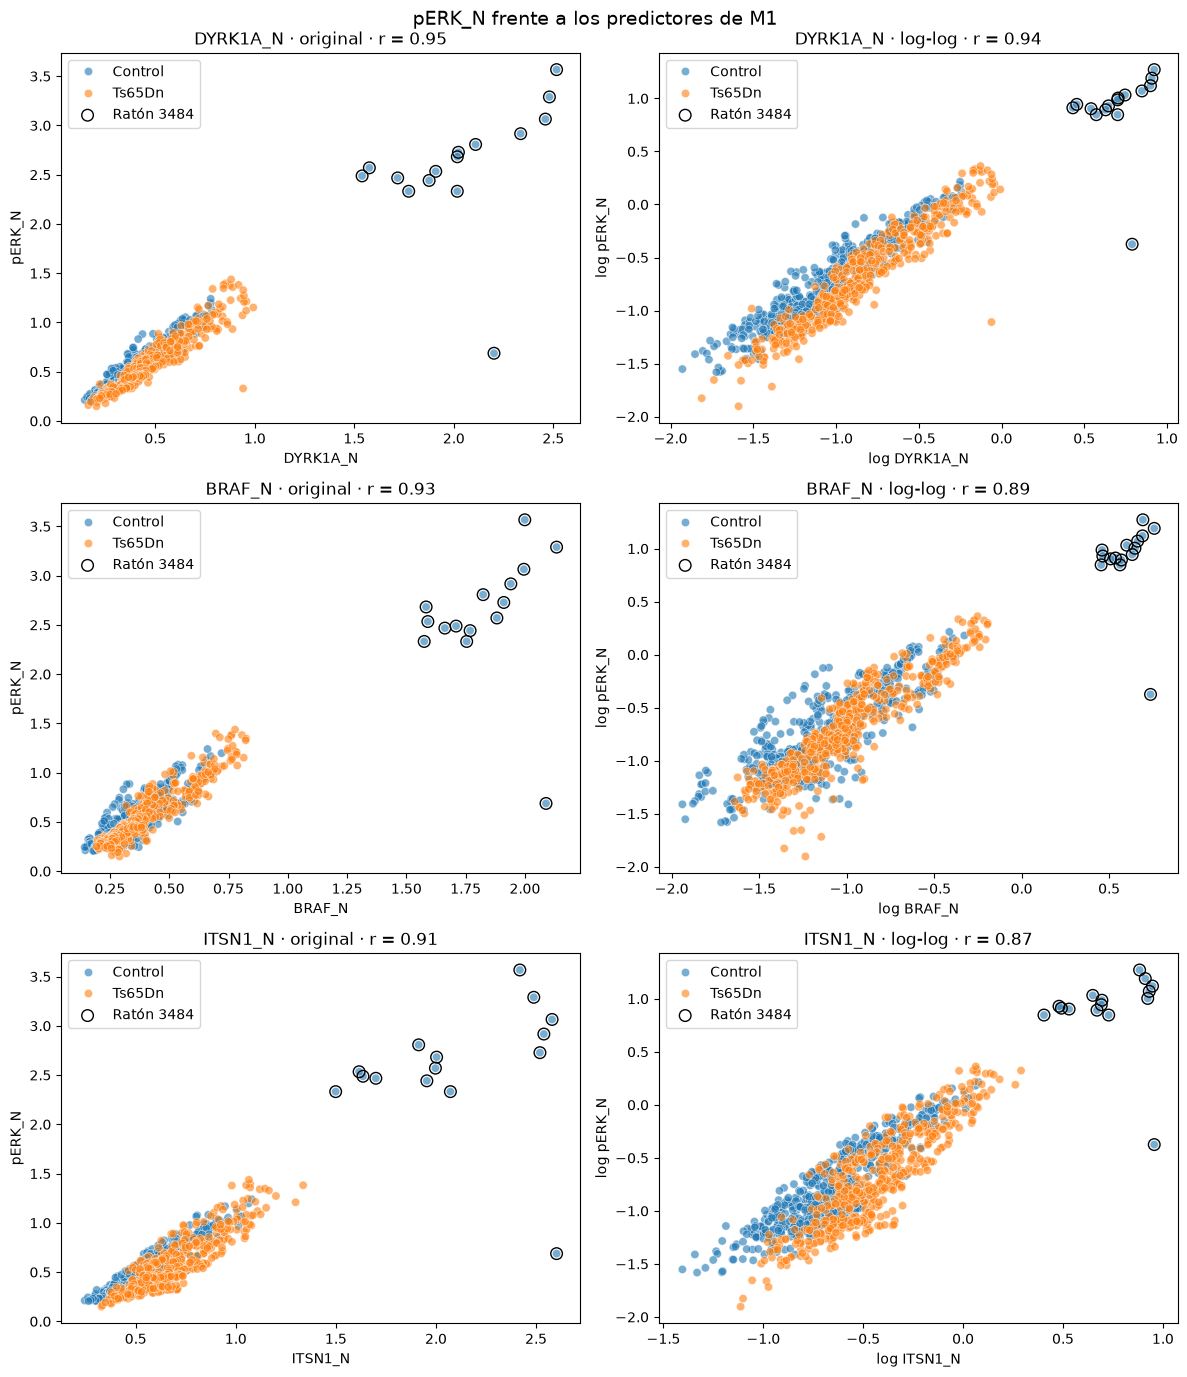

In [5]:
# Versión log-log: se transforman la objetivo y los predictores
df_log = np.log(df[[OBJETIVO] + PREDICTORES_M1]).assign(Genotype=df["Genotype"])
escalas = {"original": df, "log-log": df_log}
es_3484 = df[GRUPO] == "3484"

fig, axs = plt.subplots(3, 2, figsize=(12, 14))
for fila, proteina in zip(axs, PREDICTORES_M1):
    for ax, (escala, datos) in zip(fila, escalas.items()):
        sns.scatterplot(data=datos, x=proteina, y=OBJETIVO, hue="Genotype", alpha=0.6, ax=ax)
        ax.scatter(datos.loc[es_3484, proteina], datos.loc[es_3484, OBJETIVO],
                   facecolors="none", edgecolors="black", s=70, label="Ratón 3484")

        r = datos[proteina].corr(datos[OBJETIVO])
        prefijo = "" if escala == "original" else "log "
        ax.set(title=f"{proteina} · {escala} · r = {r:.2f}",
               xlabel=f"{prefijo}{proteina}", ylabel=f"{prefijo}{OBJETIVO}")
        ax.legend(loc="upper left")

fig.suptitle("pERK_N frente a los predictores de M1", fontsize=14)
fig.tight_layout()
plt.savefig(FIGURAS / "perk_dispersion_predictores.png", dpi=150, bbox_inches="tight")
plt.show()

> **Interpretación:** Los tres predictores muestran una relación lineal positiva con `pERK_N` en ambas escalas, y
> la correlación es incluso algo mayor en escala original (r = 0,95, 0,93 y 0,91 para `DYRK1A_N`, `BRAF_N` e
> `ITSN1_N`) que en log-log (0,94, 0,89 y 0,87). No obstante, parte de esa ventaja proviene del ratón 3484, que en
> escala original queda muy alejado sobre la prolongación de la recta y, por ello, la refuerza; sin él, las
> correlaciones en escala original bajan a 0,93, 0,90 y 0,87. Además, la réplica `3484_14` aparece aislada, con las
> tres proteínas altas pero un nivel de `pERK_N` normal, de modo que es candidata a un residuo grande con alto
> apalancamiento. Por otra parte, los genotipos forman bandas casi paralelas: para un mismo nivel de la proteína,
> los ratones Ts65Dn tienden a presentar un `pERK_N` algo menor que los controles, lo que justifica incluir
> `Genotype` en M1. En consecuencia, como ambas escalas son razonablemente lineales, la elección entre ellas se
> decide en la sección 4 con el diagnóstico de los residuos.

## 2. Partición por ratón y línea base

Se separa cerca del 20 % de los ratones como conjunto de prueba, que no se vuelve a usar hasta la sección 7. Como las
15 réplicas de un ratón no son independientes, la partición agrupa por individuo, de modo que ninguna réplica de un
ratón de prueba participe en el entrenamiento (Roberts et al., 2017); además, se estratifica por clase para que las
8 condiciones experimentales estén representadas en ambos conjuntos. Por la misma razón, toda la validación cruzada
del notebook usa `GroupKFold` con los mismos 5 pliegues.

In [6]:
# Primer pliegue de la división agrupada y estratificada = conjunto de prueba
sgfk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(sgfk.split(df, df["class"], groups=df[GRUPO]))

train = df.iloc[idx_train]
test = df.iloc[idx_test]
grupos_train = train[GRUPO]

# Ningún ratón en ambos conjuntos y todas las clases en prueba
assert set(train[GRUPO]).isdisjoint(test[GRUPO])
assert test["class"].nunique() == 8

print(f"Entrenamiento: {len(train)} filas, {train[GRUPO].nunique()} ratones")
print(f"Prueba: {len(test)} filas, {test[GRUPO].nunique()} ratones")
test.groupby("class", observed=True)[GRUPO].nunique()

Entrenamiento: 867 filas, 58 ratones
Prueba: 210 filas, 14 ratones


class
c-CS-m    2
c-CS-s    2
c-SC-m    2
c-SC-s    2
t-CS-m    2
t-CS-s    1
t-SC-m    1
t-SC-s    2
Name: raton, dtype: int64

In [7]:
# Esquema de validación único para todo el notebook 

cv = GroupKFold(n_splits=5)

METRICAS = {
    "R2": "r2",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error"
}

# Línea base: predice siempre la media de entrenamiento
base = cross_validate(DummyRegressor(strategy="mean"), train[PREDICTORES_M1], train[OBJETIVO],
                      groups=grupos_train, cv=cv, scoring=METRICAS)

# sklearn devuelve los errores con signo negativo; se invierten para reportarlos
resumen_base = pd.DataFrame({
    metrica: (base[f"test_{metrica}"] if metrica == "R2" else -base[f"test_{metrica}"])
    for metrica in METRICAS
}).agg(["mean", "std"]).round(3)
resumen_base

,R2,MSE,RMSE,MAE
mean,-0.373,0.132,0.315,0.226
std,0.728,0.182,0.204,0.086


> **Interpretación:** La línea base, que predice siempre la media de `pERK_N` del entrenamiento, obtiene un RMSE de
> 0,315 ± 0,204 y un MAE de 0,226 ± 0,086 en la validación cruzada por ratón; este es el error de no usar ningún
> predictor, y todo modelo posterior debe superarlo. Su R² medio es negativo (−0,373), lo que es esperable, ya que
> la media del entrenamiento no coincide con la media de cada pliegue de validación y R² < 0 indica justamente un
> desempeño peor que el de esa media. Además, la desviación entre pliegues es grande porque el pliegue que contiene
> al ratón 3484 concentra errores mucho mayores que el resto.

## 3. Regresión lineal múltiple inferencial (M1)

¿Cuánto se asocia cada predictor con `pERK_N`, y cambian esas conclusiones al reconocer que las réplicas de un
mismo ratón no son independientes? M1 se ajusta con `statsmodels` sobre el entrenamiento y se calculan dos tipos
de error estándar: el ordinario y el agrupado por ratón.

In [8]:
formula = "pERK_N ~ DYRK1A_N + BRAF_N + ITSN1_N + C(Genotype) + C(Treatment) + C(Behavior)"
m1_ordinario = smf.ols(formula, data=train).fit()
m1_raton = smf.ols(formula, data=train).fit(cov_type="cluster", cov_kwds={"groups": train["raton"]}, use_t=True)

print(m1_ordinario.summary2().tables[1].round(3).to_string())
print(f"\nR² = {m1_ordinario.rsquared:.3f} · n = {int(m1_ordinario.nobs):,}")

                        Coef.  Std.Err.       t  P>|t|  [0.025  0.975]
Intercept               0.084     0.015   5.762  0.000   0.055   0.113
C(Genotype)[T.Ts65Dn]  -0.052     0.008  -6.883  0.000  -0.067  -0.037
C(Treatment)[T.Saline] -0.016     0.007  -2.207  0.028  -0.029  -0.002
C(Behavior)[T.S/C]     -0.096     0.008 -11.876  0.000  -0.112  -0.080
DYRK1A_N                0.847     0.069  12.196  0.000   0.711   0.983
BRAF_N                  0.321     0.058   5.547  0.000   0.208   0.435
ITSN1_N                 0.097     0.050   1.938  0.053  -0.001   0.196

R² = 0.918 · n = 867


In [9]:
print(m1_raton.summary2().tables[1].round(3).to_string())
print(f"\nR² = {m1_raton.rsquared:.3f} · n = {int(m1_raton.nobs):,}")

                        Coef.  Std.Err.      t  P>|t|  [0.025  0.975]
Intercept               0.084     0.051  1.660  0.102  -0.017   0.185
C(Genotype)[T.Ts65Dn]  -0.052     0.017 -2.981  0.004  -0.087  -0.017
C(Treatment)[T.Saline] -0.016     0.013 -1.169  0.247  -0.042   0.011
C(Behavior)[T.S/C]     -0.096     0.016 -6.022  0.000  -0.128  -0.064
DYRK1A_N                0.847     0.276  3.068  0.003   0.294   1.400
BRAF_N                  0.321     0.122  2.631  0.011   0.077   0.566
ITSN1_N                 0.097     0.225  0.431  0.668  -0.354   0.548

R² = 0.918 · n = 867


In [10]:
# Comparación de la incertidumbre: errores estándar ordinarios frente a agrupados por ratón
comparacion_ee = pd.DataFrame({
    "coef": m1_raton.params,
    "ee_ordinario": m1_ordinario.bse,
    "ee_raton": m1_raton.bse,
    "aumento": m1_raton.bse / m1_ordinario.bse,
    "p_ordinario": m1_ordinario.pvalues,
    "p_raton": m1_raton.pvalues,
}).round(3)

print(f"R² ajustado = {m1_raton.rsquared_adj:.3f}")
comparacion_ee

R² ajustado = 0.918


,coef,ee_ordinario,ee_raton,aumento,p_ordinario,p_raton
Intercept,0.084,0.015,0.051,3.470,0.000,0.102
C(Genotype)[T.Ts65Dn],-0.052,0.008,0.017,2.309,0.000,0.004
C(Treatment)[T.Saline],-0.016,0.007,0.013,1.887,0.028,0.247
C(Behavior)[T.S/C],-0.096,0.008,0.016,1.972,0.000,0.000
DYRK1A_N,0.847,0.069,0.276,3.975,0.000,0.003
BRAF_N,0.321,0.058,0.122,2.108,0.000,0.011
ITSN1_N,0.097,0.050,0.225,4.491,0.053,0.668


> **Interpretación:** Se ajustó M1 sobre las 867 réplicas de entrenamiento y se calcularon los errores estándar de
> dos formas: la ordinaria, que supone filas independientes, y la agrupada por ratón, que reconoce que las 15
> réplicas de un mismo individuo no son observaciones independientes (Cameron & Miller, 2015). Ambas tablas tienen
> los mismos coeficientes, ya que el método de agrupación solo cambia la incertidumbre de las estimaciones; por ello,
> las conclusiones de significancia se basan en los errores agrupados, con t de 57 grados de libertad (58 ratones).
>
> Las variables categóricas se representan como columnas 0/1, de modo que cada coeficiente es la diferencia media
> en `pERK_N` frente a su nivel de referencia (Control, Memantine y C/S), manteniendo constantes los demás
> predictores. Del mismo modo, cada coeficiente numérico indica el cambio en `pERK_N` asociado a un aumento de la
> proteína, con todo lo demás fijo; se trata de asociaciones dentro de este diseño experimental y no de efectos
> causales.
>
> | Término | Coef. | IC 95 % (por ratón) | Lectura |
> |---|---|---|---|
> | `C(Genotype)[T.Ts65Dn]` | −0,052 | [−0,087; −0,017] | Con los mismos niveles de las tres proteínas, tratamiento y conducta, los ratones Ts65Dn tienen en promedio 0,052 unidades menos de `pERK_N` que los controles, lo que coincide con las bandas paralelas de la sección 1.2 |
> | `C(Treatment)[T.Saline]` | −0,016 | [−0,042; 0,011] | Los ratones con solución salina tendrían 0,016 menos que los tratados con memantina; sin embargo, el intervalo incluye el 0, por lo que no hay evidencia de esa diferencia |
> | `C(Behavior)[T.S/C]` | −0,096 | [−0,128; −0,064] | Los ratones no estimulados para aprender tienen 0,096 menos de `pERK_N` que los estimulados; es el efecto de diseño más grande y es coherente con la activación de ERK durante el aprendizaje (Sweatt, 2004) |
> | `DYRK1A_N` | 0,847 | [0,294; 1,400] | Un aumento de 0,1 en `DYRK1A_N` se asocia con 0,085 más de `pERK_N` |
> | `BRAF_N` | 0,321 | [0,077; 0,566] | Un aumento de 0,1 en `BRAF_N` se asocia con 0,032 más de `pERK_N` |
> | `ITSN1_N` | 0,097 | [−0,354; 0,548] | El intervalo incluye el 0, de modo que no se distingue un aporte propio de esta proteína |
> | `Intercept` | 0,084 | [−0,017; 0,185] | Valor esperado para un ratón control, con memantina y estimulado, con las tres proteínas en 0; ese nivel está fuera del rango observado, por lo que no se interpreta |
>
> Por otra parte, el modelo explica el 91,8 % de la variación de `pERK_N` en el entrenamiento (R² ajustado = 0,918).
> No obstante, este valor se calcula sobre los mismos datos con que se ajustó el modelo, por lo que su desempeño
> predictivo se evalúa con validación cruzada en la sección 6.
>
> Finalmente, la tabla de comparación muestra que, al reconocer que las 15 réplicas de un ratón no son 15
> individuos, los errores estándar crecen entre 1,9 y 4,5 veces. En consecuencia, el tratamiento deja de ser
> significativo (p pasa de 0,028 a 0,247): si se hubiera usado solo el MCO ordinario, se habría concluido que la
> memantina se asocia con `pERK_N`, cuando ese resultado era un artefacto de la pseudorreplicación. Asimismo,
> `ITSN1_N` no resulta significativa (p = 0,668) a pesar de su alta correlación con `pERK_N` (ρ = 0,83), puesto que
> comparte casi toda su información con `DYRK1A_N` (ρ = 0,93) y el modelo no puede separar el aporte de cada una;
> esta colinealidad se cuantifica con el VIF en la sección 4.
>
> Por último, cabe recordar que estos coeficientes están en la escala original de las variables. Como muestra la
> sección 4, la escala log-log resulta más adecuada para estos datos, por lo que la lectura definitiva de M1 se
> presenta en la sección 4.7.

## 4. Supuestos, multicolinealidad e influencia

Los supuestos de M1 se evalúan con un gráfico y, cuando existe, con una prueba: Breusch-Pagan para la
homocedasticidad (Breusch & Pagan, 1979), Jarque-Bera para la normalidad de los residuos (Jarque & Bera, 1987) y
Durbin-Watson para la independencia (Durbin & Watson, 1950). Sin embargo, con 867 filas cualquier prueba rechaza
desviaciones pequeñas, por lo que el gráfico prima sobre el valor p. Todos los diagnósticos se calculan sobre el
entrenamiento y, como la sección 1.2 dejó abierta la escala, se repiten para M1 en log-log con el fin de comparar
ambas versiones.

### 4.1 Funciones de diagnóstico

In [11]:
def graficar_linealidad(modelo, variables, titulo, archivo):
    """Residuos parciales (CCPR) de cada predictor numérico: la nube debe seguir la recta."""
    fig, axs = plt.subplots(1, len(variables), figsize=(5 * len(variables), 4.5))
    for ax, variable in zip(axs, variables):
        sm.graphics.plot_ccpr(modelo, variable, ax=ax)
        ax.set(title=variable, xlabel=variable, ylabel="Residuo + componente")
    fig.suptitle(titulo, fontsize=13)
    fig.tight_layout()
    plt.savefig(FIGURAS / archivo, dpi=150, bbox_inches="tight")
    plt.show()


def graficar_residuos(modelo, grupos, titulo, archivo):
    """Figura 2×2: residuos vs. ajustados, escala-ubicación, Q-Q y residuos por ratón."""
    ajustados = modelo.fittedvalues
    residuos = modelo.resid
    estandarizados = modelo.get_influence().resid_studentized_internal

    fig, axs = plt.subplots(2, 2, figsize=(13, 9))

    # Linealidad e independencia de la media: sin patrón alrededor de 0
    axs[0, 0].scatter(ajustados, residuos, s=6, alpha=0.3)
    axs[0, 0].axhline(0, color="black", linewidth=1)
    axs[0, 0].set(title="Residuos vs. ajustados", xlabel="Valor ajustado", ylabel="Residuo")

    # Homocedasticidad: dispersión constante a lo largo de los ajustados
    axs[0, 1].scatter(ajustados, np.sqrt(np.abs(estandarizados)), s=6, alpha=0.3)
    axs[0, 1].set(title="Escala-ubicación", xlabel="Valor ajustado", ylabel="√|residuo estandarizado|")

    # Normalidad: puntos sobre la diagonal
    sm.qqplot(estandarizados, line="45", ax=axs[1, 0], markersize=3, alpha=0.5)
    axs[1, 0].set(title="Q-Q de residuos estandarizados", xlabel="Cuantiles teóricos",
                  ylabel="Cuantiles muestrales")

    # Independencia: residuos agrupados por ratón, ordenados por su mediana
    por_raton = pd.DataFrame({"residuo": residuos, "raton": grupos})
    orden = por_raton.groupby("raton")["residuo"].median().sort_values().index
    sns.boxplot(data=por_raton, x="raton", y="residuo", order=orden, ax=axs[1, 1], fliersize=2)
    axs[1, 1].axhline(0, color="black", linewidth=1)
    axs[1, 1].set(title="Residuos por ratón", xlabel="Ratón (ordenado por mediana)", ylabel="Residuo")
    axs[1, 1].tick_params(axis="x", labelbottom=False)

    fig.suptitle(titulo, fontsize=13)
    fig.tight_layout()
    plt.savefig(FIGURAS / archivo, dpi=150, bbox_inches="tight")
    plt.show()


def pruebas_supuestos(modelo, grupos):
    """Breusch-Pagan, Jarque-Bera, Durbin-Watson (filas ordenadas por ratón) y varianza residual entre ratones."""
    residuos = modelo.resid
    _, p_bp, _, _ = het_breuschpagan(residuos, modelo.model.exog)
    jb, p_jb, asimetria, curtosis = jarque_bera(residuos)
    orden_raton = grupos.sort_values(kind="stable").index
    entre_ratones = residuos.groupby(grupos).transform("mean").var() / residuos.var()
    return pd.Series({
        "Breusch-Pagan (p)": p_bp,
        "Jarque-Bera (p)": p_jb,
        "Asimetría de residuos": asimetria,
        "Curtosis de residuos": curtosis,
        "Durbin-Watson": durbin_watson(residuos.loc[orden_raton]),
        "Varianza residual entre ratones": entre_ratones,
    })

### 4.2 Linealidad, homocedasticidad, normalidad e independencia (M1 en escala original)

¿Los residuos de M1 cumplen los supuestos de la regresión lineal?

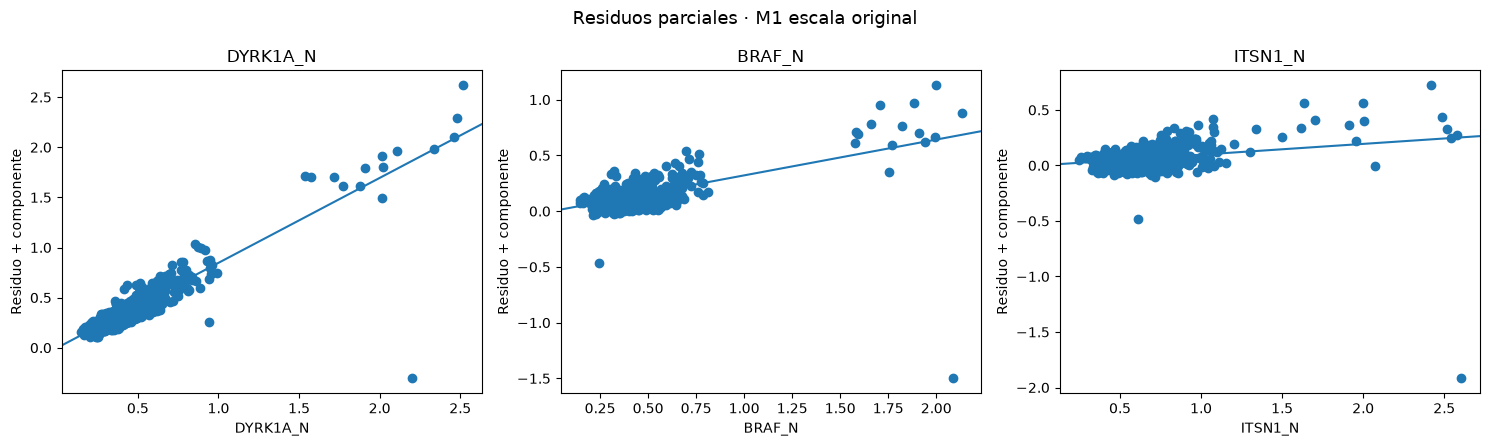

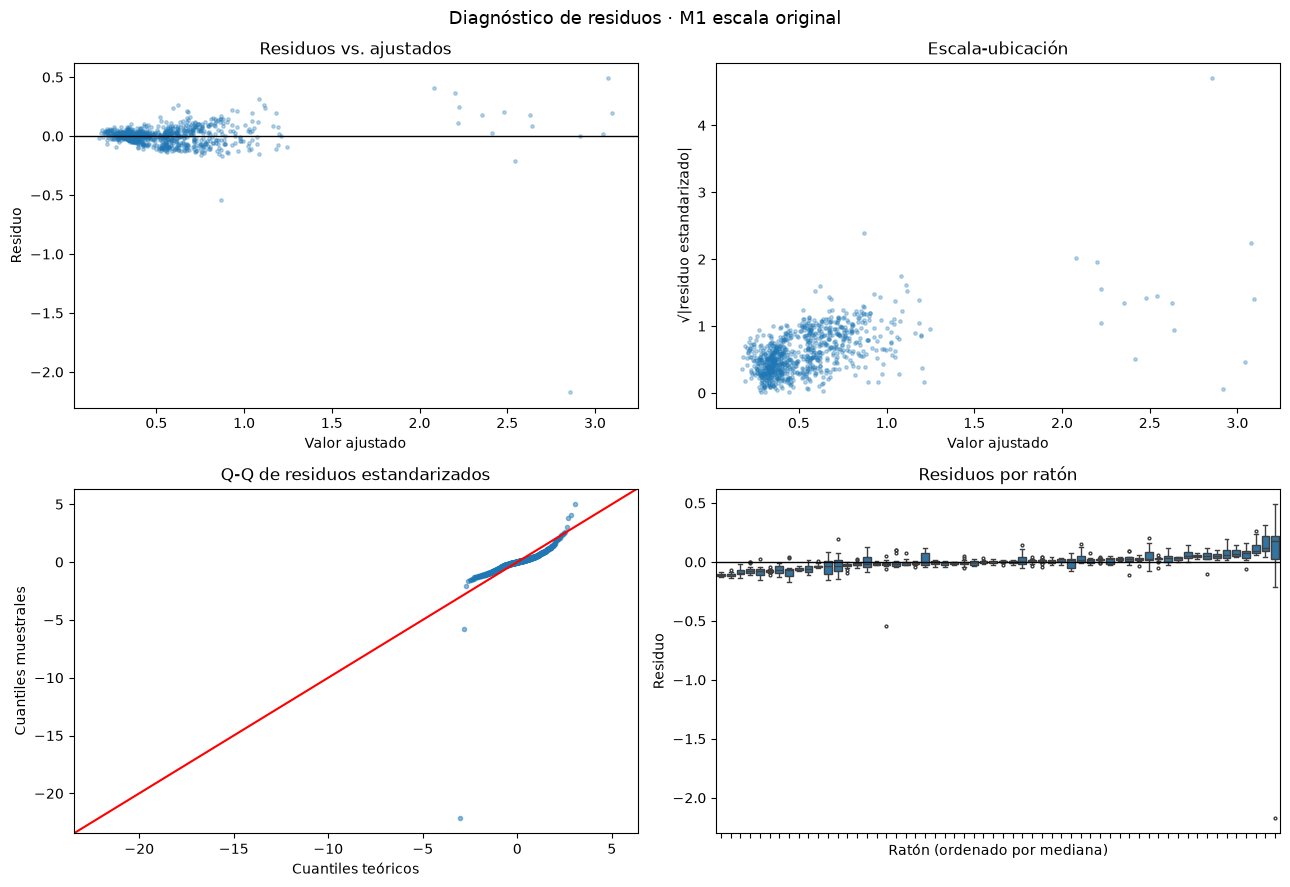

In [12]:
graficar_linealidad(m1_raton, PREDICTORES_M1, "Residuos parciales · M1 escala original",
                    "m1_linealidad_original.png")
graficar_residuos(m1_raton, grupos_train, "Diagnóstico de residuos · M1 escala original",
                  "m1_residuos_original.png")

> **Interpretación:** Los residuos parciales siguen una recta en las tres proteínas, sin curvatura, de modo que la
> linealidad se cumple una vez descontados los demás predictores; las excepciones son las réplicas del ratón 3484,
> que quedan muy a la derecha sobre la prolongación de la recta, y la réplica `3484_14`, muy por debajo de ella.
> Sin embargo, los demás supuestos no se cumplen. En primer lugar, la dispersión de los residuos crece con el valor
> ajustado, como muestran la forma de abanico y la nube ascendente del gráfico de escala-ubicación, lo que indica
> heterocedasticidad. En segundo lugar, el Q-Q se aleja de la diagonal en ambos extremos y `3484_14` queda a unas
> 22 desviaciones, por lo que los residuos no son normales. Por último, en el gráfico por ratón muchas cajas quedan
> completas por encima o por debajo de 0; es decir, las réplicas de un mismo ratón se equivocan en la misma
> dirección y, por tanto, no son independientes.

### 4.3 Multicolinealidad

¿Los predictores de M1 comparten tanta información que sus coeficientes se vuelven inestables? Se calcula el VIF
sobre la matriz de diseño del modelo, que ya incluye la constante y las variables de diseño; se toman 5 y 10 como
valores de referencia (James et al., 2023).

In [13]:
# Matriz de diseño de M1 (entrenamiento), con la columna Intercept que exige el VIF
matriz = m1_raton.model.exog
nombres = m1_raton.model.exog_names

vif = pd.Series(
    [variance_inflation_factor(matriz, i) for i in range(1, matriz.shape[1])],
    index=nombres[1:], name="VIF",
).sort_values(ascending=False).round(2)
vif

DYRK1A_N                  27.12
BRAF_N                    14.30
ITSN1_N                   14.19
C(Behavior)[T.S/C]         1.32
C(Genotype)[T.Ts65Dn]      1.15
C(Treatment)[T.Saline]     1.01
Name: VIF, dtype: float64

> **Interpretación:** Las tres proteínas superan el umbral de 10 (`DYRK1A_N` = 27,1; `BRAF_N` = 14,3;
> `ITSN1_N` = 14,2), lo que confirma una colinealidad severa entre ellas, coherente con sus correlaciones de la
> Actividad 1. La colinealidad no afecta las predicciones ni el R², pero sí la fiabilidad de los coeficientes
> individuales: como el modelo no puede separar el aporte de proteínas que varían juntas, sus errores estándar se
> inflan y sus valores cambian con pequeñas variaciones en los datos (James et al., 2023), como se confirma en la
> sección 4.4. En cambio, las variables de
> diseño tienen VIF cercanos a 1, es decir, casi no se relacionan con los demás predictores, lo que es esperable en
> un diseño experimental balanceado.

### 4.4 Influencia

¿Hay réplicas que, por sí solas, determinan los coeficientes? Se combinan el apalancamiento (umbral 2p/n), el
residuo estudentizado y la distancia de Cook (umbral 4/n; Cook, 1977).

In [14]:
influencia = m1_raton.get_influence()
n, p = int(m1_raton.nobs), int(m1_raton.df_model) + 1

medidas = pd.DataFrame({
    "MouseID": train["MouseID"],
    "class": train["class"],
    "apalancamiento": influencia.hat_matrix_diag,
    "residuo_estudentizado": influencia.resid_studentized_external,
    "cook": influencia.cooks_distance[0],
})

umbral_apal, umbral_cook = 2 * p / n, 4 / n
print(f"Umbrales: apalancamiento > {umbral_apal:.3f} | Cook > {umbral_cook:.4f}")
print(f"Réplicas sobre el umbral de Cook: {(medidas['cook'] > umbral_cook).sum()} de {n}")
print(f"De ellas, del ratón 3484: {((medidas['cook'] > umbral_cook) & (train[GRUPO] == '3484')).sum()}")

medidas.sort_values("cook", ascending=False).head(10).round(3)

Umbrales: apalancamiento > 0.016 | Cook > 0.0046
Réplicas sobre el umbral de Cook: 21 de 867
De ellas, del ratón 3484: 12


,MouseID,class,apalancamiento,residuo_estudentizado,cook
373,3484_14,c-CS-s,0.098,-33.653,7.621
782,3530_3,t-SC-m,0.172,-5.860,0.984
372,3484_13,c-CS-s,0.103,5.075,0.409
369,3484_10,c-CS-s,0.134,3.866,0.325
366,3484_7,c-CS-s,0.073,4.137,0.189
360,3484_1,c-CS-s,0.087,1.958,0.052
367,3484_8,c-CS-s,0.050,2.437,0.044
370,3484_11,c-CS-s,0.083,1.827,0.043
363,3484_4,c-CS-s,0.078,1.818,0.040
364,3484_5,c-CS-s,0.061,2.016,0.037


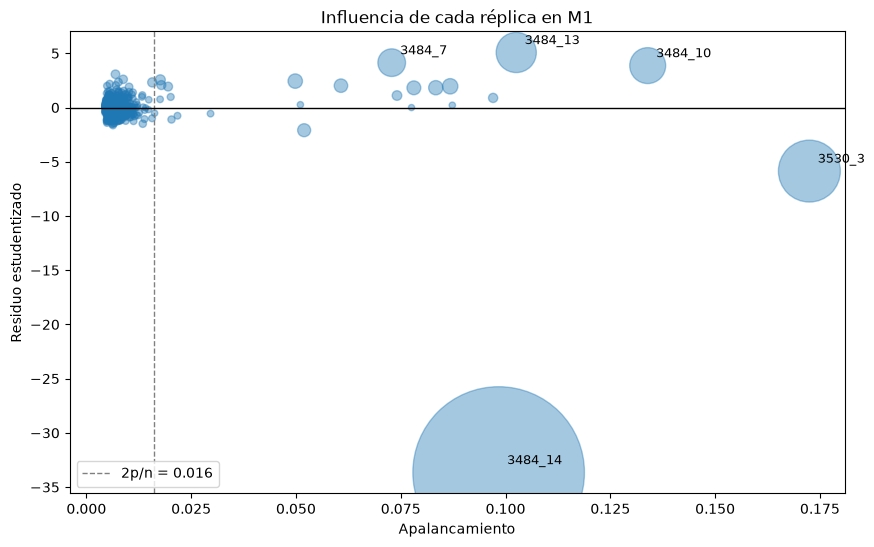

In [15]:
# Apalancamiento frente a residuo estudentizado; el tamaño del punto es proporcional a la distancia de Cook
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(medidas["apalancamiento"], medidas["residuo_estudentizado"],
           s=20 + 2000 * medidas["cook"], alpha=0.4)
ax.axvline(umbral_apal, color="gray", linestyle="--", linewidth=1, label=f"2p/n = {umbral_apal:.3f}")
ax.axhline(0, color="black", linewidth=1)

# Etiqueta de las cinco réplicas más influyentes
for _, fila in medidas.nlargest(5, "cook").iterrows():
    ax.annotate(fila["MouseID"], (fila["apalancamiento"], fila["residuo_estudentizado"]),
                textcoords="offset points", xytext=(6, 6), fontsize=9)

ax.set(title="Influencia de cada réplica en M1", xlabel="Apalancamiento", ylabel="Residuo estudentizado")
ax.legend(loc="lower left")
plt.savefig(FIGURAS / "m1_influencia.png", dpi=150, bbox_inches="tight")
plt.show()

> **Interpretación:** La mayoría de las réplicas tiene un apalancamiento bajo (por debajo de 0,016) y residuos
> moderados, por lo que ninguna de ellas modifica el ajuste por sí sola. Por el contrario, las réplicas del ratón
> 3484 tienen un apalancamiento alto, ya que sus niveles de proteína son muy superiores al resto, y 12 de las 21
> réplicas que superan el umbral de Cook pertenecen a este ratón. En particular, `3484_14` combina un
> apalancamiento alto con un residuo estudentizado de −33,7, porque tiene las tres proteínas elevadas pero un
> `pERK_N` normal; en consecuencia, su distancia de Cook (7,6) supera unas 1.600 veces el umbral 4/n y la réplica
> arrastra la recta hacia sí. La segunda réplica más influyente, `3530_3` (Cook = 0,98), corresponde al punto
> aislado de la sección 1.2.

In [16]:
# Sensibilidad: M1 sin el ratón 3484 (no se elimina del análisis; solo se mide cuánto pesa)
train_sin_3484 = train[train[GRUPO] != "3484"]
m1_sin_3484 = smf.ols(formula, data=train_sin_3484).fit(
    cov_type="cluster", cov_kwds={"groups": train_sin_3484[GRUPO]}, use_t=True)

sensibilidad_3484 = pd.DataFrame({
    "coef_con": m1_raton.params,
    "coef_sin": m1_sin_3484.params,
    "p_con": m1_raton.pvalues,
    "p_sin": m1_sin_3484.pvalues,
}).round(3)
print(f"R² con 3484 = {m1_raton.rsquared:.3f} | sin 3484 = {m1_sin_3484.rsquared:.3f}")
sensibilidad_3484

R² con 3484 = 0.918 | sin 3484 = 0.920


,coef_con,coef_sin,p_con,p_sin
Intercept,0.084,0.021,0.102,0.557
C(Genotype)[T.Ts65Dn],-0.052,-0.062,0.004,0.000
C(Treatment)[T.Saline],-0.016,-0.017,0.247,0.190
C(Behavior)[T.S/C],-0.096,-0.089,0.000,0.000
DYRK1A_N,0.847,0.563,0.003,0.008
BRAF_N,0.321,0.408,0.011,0.002
ITSN1_N,0.097,0.345,0.668,0.006


> **Interpretación:** Sin el ratón 3484, el R² apenas cambia (0,918 frente a 0,920), ya que depende de la fuerte
> relación entre las proteínas y `pERK_N` y no de un individuo. Sin embargo, los coeficientes sí cambian de forma
> marcada: `DYRK1A_N` baja de 0,847 a 0,563, `BRAF_N` sube de 0,321 a 0,408 e `ITSN1_N` pasa de 0,097
> (p = 0,668) a 0,345 (p = 0,006). Por tanto, en escala original un solo ratón decide qué proteína parece
> importar, lo que es la consecuencia práctica de combinar una colinealidad severa con observaciones muy
> influyentes. El ratón se conserva según la decisión de la Actividad 1, pero este resultado obliga a buscar una
> especificación menos sensible a él.

### 4.5 M1 en escala log-log

Se ajusta la misma especificación con el logaritmo de `pERK_N` y de las tres proteínas, y se repite el diagnóstico.
En este modelo, cada coeficiente de una proteína se lee como elasticidad: un aumento del 1 % en la proteína se asocia
con un cambio de β % en `pERK_N`, manteniendo constante lo demás.

In [17]:
formula_log = ("np.log(pERK_N) ~ np.log(DYRK1A_N) + np.log(BRAF_N) + np.log(ITSN1_N)"
               " + C(Genotype) + C(Treatment) + C(Behavior)")
m1_log = smf.ols(formula_log, data=train).fit(
    cov_type="cluster", cov_kwds={"groups": train[GRUPO]}, use_t=True)

print(m1_log.summary2().tables[1].round(3).to_string())
print(f"\nR² = {m1_log.rsquared:.3f} (escala log, no comparable directamente con el R² de M1 original)")

                        Coef.  Std.Err.      t  P>|t|  [0.025  0.975]
Intercept               0.315     0.040  7.911  0.000   0.235   0.395
C(Genotype)[T.Ts65Dn]  -0.114     0.028 -4.050  0.000  -0.170  -0.058
C(Treatment)[T.Saline] -0.045     0.025 -1.786  0.079  -0.096   0.005
C(Behavior)[T.S/C]     -0.215     0.039 -5.445  0.000  -0.294  -0.136
np.log(DYRK1A_N)        0.551     0.128  4.299  0.000   0.294   0.808
np.log(BRAF_N)          0.196     0.078  2.524  0.014   0.041   0.351
np.log(ITSN1_N)         0.232     0.122  1.903  0.062  -0.012   0.477

R² = 0.930 (escala log, no comparable directamente con el R² de M1 original)


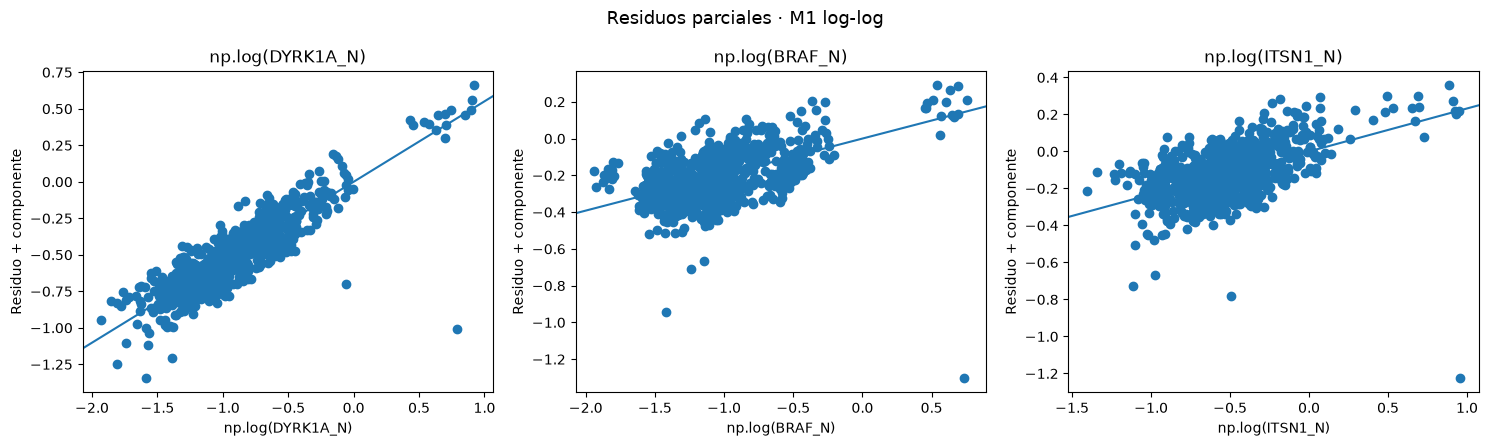

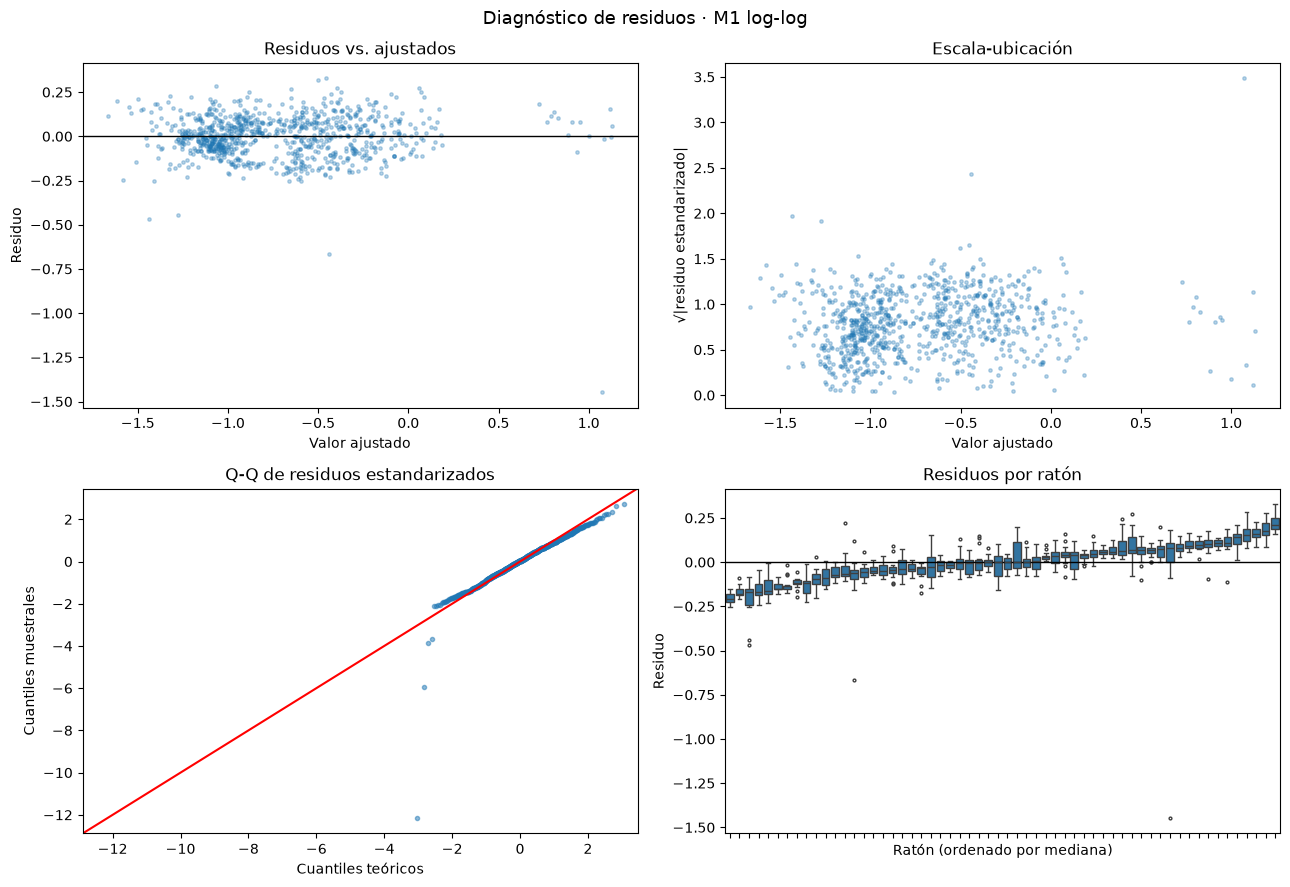

In [18]:
predictores_log = [f"np.log({p})" for p in PREDICTORES_M1]
graficar_linealidad(m1_log, predictores_log, "Residuos parciales · M1 log-log", "m1_linealidad_log.png")
graficar_residuos(m1_log, grupos_train, "Diagnóstico de residuos · M1 log-log", "m1_residuos_log.png")

In [19]:
# Sensibilidad de M1 log-log al ratón 3484 y distancia de Cook en ambas escalas
m1_log_sin_3484 = smf.ols(formula_log, data=train_sin_3484).fit(
    cov_type="cluster", cov_kwds={"groups": train_sin_3484[GRUPO]}, use_t=True)
cook_log = m1_log.get_influence().cooks_distance[0]

sensibilidad_log = pd.DataFrame({
    "coef_con": m1_log.params,
    "coef_sin": m1_log_sin_3484.params,
    "p_con": m1_log.pvalues,
    "p_sin": m1_log_sin_3484.pvalues,
}).round(3)

print(f"Cook máxima: original = {medidas['cook'].max():.2f} | log-log = {cook_log.max():.2f}")
print(f"Réplicas sobre 4/n: original = {(medidas['cook'] > umbral_cook).sum()} | "
      f"log-log = {(cook_log > umbral_cook).sum()}")
sensibilidad_log

Cook máxima: original = 7.62 | log-log = 0.94
Réplicas sobre 4/n: original = 21 | log-log = 31


,coef_con,coef_sin,p_con,p_sin
Intercept,0.315,0.335,0.000,0.000
C(Genotype)[T.Ts65Dn],-0.114,-0.121,0.000,0.000
C(Treatment)[T.Saline],-0.045,-0.042,0.079,0.108
C(Behavior)[T.S/C],-0.215,-0.205,0.000,0.000
np.log(DYRK1A_N),0.551,0.531,0.000,0.000
np.log(BRAF_N),0.196,0.213,0.014,0.012
np.log(ITSN1_N),0.232,0.272,0.062,0.025


> **Interpretación:** En escala log-log, los residuos parciales siguen siendo lineales y, además, los demás
> supuestos mejoran con claridad. Por un lado, la dispersión de los residuos es pareja a lo largo de los valores
> ajustados, de modo que el gráfico de escala-ubicación queda casi plano; por otro, el Q-Q sigue la diagonal salvo
> unos pocos puntos, y `3484_14` pasa de unas 22 a unas 12 desviaciones. Asimismo, el modelo deja de depender del
> ratón 3484: sin él, los coeficientes casi no cambian (`DYRK1A_N`: 0,551 frente a 0,531; `BRAF_N`: 0,196 frente a
> 0,213; `ITSN1_N`: 0,232 frente a 0,272), y la distancia de Cook máxima baja de 7,6 a 0,94. Aunque más réplicas
> superan el umbral 4/n (31 frente a 21), ninguna domina el ajuste; es decir, la influencia queda repartida en
> lugar de concentrarse en una sola réplica.

### 4.6 Comparación de los supuestos en ambas escalas

In [20]:
comparacion_supuestos = pd.DataFrame({
    "M1 original": pruebas_supuestos(m1_raton, grupos_train),
    "M1 log-log": pruebas_supuestos(m1_log, grupos_train),
}).round(3)
comparacion_supuestos

,M1 original,M1 log-log
Breusch-Pagan (p),0.000,0.000
Jarque-Bera (p),0.000,0.000
Asimetría de residuos,-10.562,-2.196
Curtosis de residuos,230.691,26.427
Durbin-Watson,1.653,0.753
Varianza residual entre ratones,0.238,0.618


> **Interpretación:** Las pruebas de Breusch-Pagan y Jarque-Bera rechazan sus hipótesis nulas (varianza constante
> y normalidad) en ambas escalas; no obstante, con 867 filas detectan desviaciones mínimas, por lo que la magnitud
> se juzga con los gráficos y con la forma de los residuos. En ese sentido, la escala log-log reduce la asimetría de
> −10,6 a −2,2 y la curtosis de 231 a 26 (3 en una normal), de modo que las colas siguen siendo pesadas pero mucho
> menos extremas. Por el contrario, el Durbin-Watson baja de 1,65 a 0,75 y la proporción de la varianza residual
> que está entre ratones sube del 24 % al 62 %. Esto no indica que el modelo log-log sea peor: en escala original,
> una sola réplica (`3484_14`) concentra tanto error que oculta la dependencia entre réplicas, y al reducir su peso
> aparece la estructura por ratón que siempre estuvo presente. Esa dependencia ya está cubierta por los errores
> estándar agrupados (sección 3) y lo estará por la validación con `GroupKFold` (sección 6).

### 4.7 Decisión sobre la escala de M1

| Supuesto | M1 escala original | M1 log-log | Implicación |
|---|---|---|---|
| Linealidad | Se cumple, salvo réplicas del 3484 | Se cumple | Ambas escalas son válidas para una relación lineal |
| Homocedasticidad | No: la dispersión crece con el ajustado | Mejora: dispersión pareja | Los intervalos se calculan con errores robustos en ambos casos |
| Normalidad de residuos | No: asimetría −10,6 y curtosis 231 | Mejora: asimetría −2,2 y curtosis 26 | Con 58 ratones, la inferencia se apoya en los errores robustos más que en la normalidad |
| Independencia | No: residuos agrupados por ratón | No: la dependencia se hace visible | Errores agrupados por ratón y `GroupKFold` |
| Multicolinealidad | VIF entre 14 y 27 | — | Coeficientes individuales poco estables; se evalúa la regularización en la sección 5 |
| Influencia | `3484_14` con Cook = 7,6; coeficientes muy sensibles al ratón 3484 | Cook máxima = 0,94; coeficientes estables | La escala log-log no depende de un solo individuo |

En consecuencia, se adopta M1 en escala log-log, ya que mejora la homocedasticidad y la normalidad de los residuos
y, sobre todo, produce coeficientes estables frente al ratón 3484, que se conserva en el análisis. En esta escala,
cada coeficiente de una proteína se lee como una elasticidad, y cada coeficiente de diseño β como un cambio
porcentual de (e^β − 1) × 100 en `pERK_N`, manteniendo constantes los demás predictores:

| Término | Coef. | IC 95 % (por ratón) | Lectura |
|---|---|---|---|
| `np.log(DYRK1A_N)` | 0,551 | [0,294; 0,808] | Un 1 % más de `DYRK1A_N` se asocia con un 0,55 % más de `pERK_N` |
| `np.log(BRAF_N)` | 0,196 | [0,041; 0,351] | Un 1 % más de `BRAF_N` se asocia con un 0,20 % más de `pERK_N` |
| `np.log(ITSN1_N)` | 0,232 | [−0,012; 0,477] | El intervalo incluye el 0 (p = 0,062), por lo que su aporte propio no se distingue del de `DYRK1A_N` |
| `C(Genotype)[T.Ts65Dn]` | −0,114 | [−0,170; −0,058] | Los ratones Ts65Dn tienen en promedio un 10,8 % menos de `pERK_N` que los controles |
| `C(Behavior)[T.S/C]` | −0,215 | [−0,294; −0,136] | Los ratones no estimulados para aprender tienen un 19,3 % menos de `pERK_N` que los estimulados |
| `C(Treatment)[T.Saline]` | −0,045 | [−0,096; 0,005] | El intervalo incluye el 0 (p = 0,079): no hay evidencia de diferencia entre salina y memantina |

Por último, el R² de este modelo (0,930) está en escala logarítmica y no se compara directamente con el del modelo
original; la comparación de desempeño se hace en la sección 6, con las métricas en la escala original de `pERK_N`.

## 5. Modelos regularizados (M2)

¿Mejora la predicción de `pERK_N` al usar las 75 proteínas restantes con regularización? M2 se ajusta en la misma
escala log-log que M1 (sección 4.7): el preprocesador aplica el logaritmo a las proteínas antes de escalarlas e
imputarlas, y `TransformedTargetRegressor` ajusta el modelo sobre `log(pERK_N)` pero devuelve las predicciones en la
escala original, de modo que las métricas se comparan directamente con la línea base. Todo el preprocesamiento va
dentro del `Pipeline`, para que solo aprenda del entrenamiento de cada pliegue (Kuhn & Johnson, 2019).

In [21]:
# Preprocesador de M2: log → escalado → imputación KNN en proteínas; una columna 0/1 por variable de diseño
prep = ColumnTransformer([
    ("num", Pipeline([
        ("log", FunctionTransformer(np.log, feature_names_out="one-to-one")),
        ("escala", StandardScaler()),
        ("imputa", KNNImputer()),
    ]), PROTEINAS_M2),
    ("cat", OneHotEncoder(drop="if_binary"), DISENO),
], verbose_feature_names_out=False)

# Datos de M2: todas las proteínas menos la objetivo, más las variables de diseño
X_train = train[PROTEINAS_M2 + DISENO]
y_train = train[OBJETIVO]

# Verificación: 75 proteínas + 3 columnas de diseño
assert prep.fit_transform(X_train).shape == (len(X_train), 78)

### 5.1 Búsqueda de hiperparámetros

Los tres modelos se ajustan con la misma función: cada α se evalúa con la validación agrupada por ratón y solo con
el entrenamiento. Las grillas difieren porque la penalización L1 de Lasso y Elastic Net anula todos los coeficientes
con α mucho menores que los de Ridge; en cada caso se verifica que el α elegido no quede en el borde de la grilla.
En Elastic Net se busca además `l1_ratio`, que mezcla las penalizaciones de Ridge (0) y Lasso (1) (Zou & Hastie, 2005).

In [22]:
def buscar_hiperparametros(modelo, grilla, nombre, archivo):
    """Busca los hiperparámetros de un modelo de M2 con validación agrupada y grafica el RMSE frente a α."""
    pipe = TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep), ("modelo", modelo)]),
        func=np.log, inverse_func=np.exp)
    busqueda = GridSearchCV(pipe, grilla, cv=cv, scoring="neg_root_mean_squared_error")
    busqueda.fit(X_train, y_train, groups=grupos_train)

    resultados = pd.DataFrame(busqueda.cv_results_)
    de_mejor = resultados.loc[busqueda.best_index_, "std_test_score"]

    # Con más de un hiperparámetro, la curva se dibuja con los demás fijos en su mejor valor
    for parametro, valor in busqueda.best_params_.items():
        if not parametro.endswith("alpha"):
            resultados = resultados[resultados[f"param_{parametro}"] == valor]
    alphas = resultados["param_regressor__modelo__alpha"].astype(float)
    rmse = -resultados["mean_test_score"]
    rmse_de = resultados["std_test_score"]
    alpha_mejor = busqueda.best_params_["regressor__modelo__alpha"]

    elegidos = ", ".join(f"{p.split('__')[-1]} = {v:.4g}" for p, v in busqueda.best_params_.items())
    print(f"{nombre} · {elegidos} | RMSE de validación: {-busqueda.best_score_:.4f} ± {de_mejor:.4f}")
    if alpha_mejor in (alphas.min(), alphas.max()):
        print("Advertencia: α quedó en el borde de la grilla; conviene ampliarla.")

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(alphas, rmse, marker="o")
    ax.fill_between(alphas, rmse - rmse_de, rmse + rmse_de, alpha=0.2)
    ax.axvline(alpha_mejor, color="gray", linestyle="--", label=f"α elegido = {alpha_mejor:.4g}")
    ax.set(xscale="log", title=f"{nombre} · error de validación frente a α", xlabel="α (escala log)",
           ylabel="RMSE de validación (pERK_N)")
    ax.legend()
    plt.savefig(FIGURAS / archivo, dpi=150, bbox_inches="tight")
    plt.show()
    return busqueda

Ridge · alpha = 35.62 | RMSE de validación: 0.0748 ± 0.0621


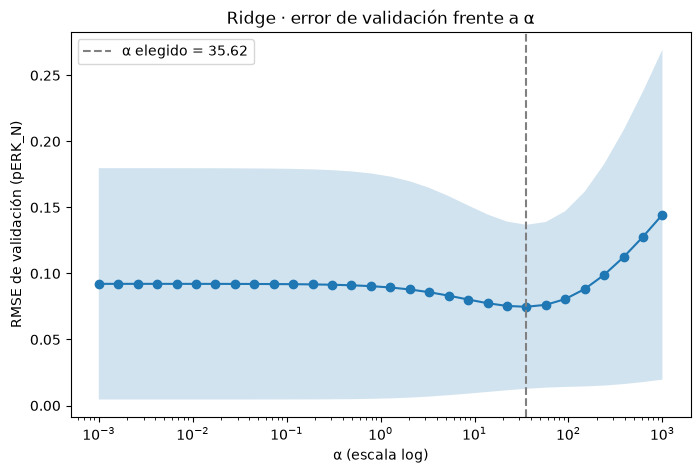

In [23]:
busqueda_ridge = buscar_hiperparametros(
    Ridge(), {"regressor__modelo__alpha": np.logspace(-3, 3, 30)},
    "Ridge", "ridge_alpha.png")

> **Interpretación:** La curva de Ridge tiene forma de U, que es la idea central de la regularización. Con α muy
> pequeño, el modelo se acerca a MCO sin penalizar y el RMSE de validación es de 0,092, ya que con 78 predictores
> colineales y solo 58 ratones de entrenamiento se ajusta en exceso al ruido de los pliegues. A medida que α crece,
> la penalización reduce los coeficientes y el error baja hasta su mínimo, 0,0748 con α ≈ 35,6; a partir de ahí,
> la penalización empieza a anular información útil y el error vuelve a subir, hasta 0,145 con α = 1.000. El α
> elegido queda en el interior de la grilla, por lo que esta es suficiente.

Lasso · alpha = 0.002212 | RMSE de validación: 0.0738 ± 0.0645


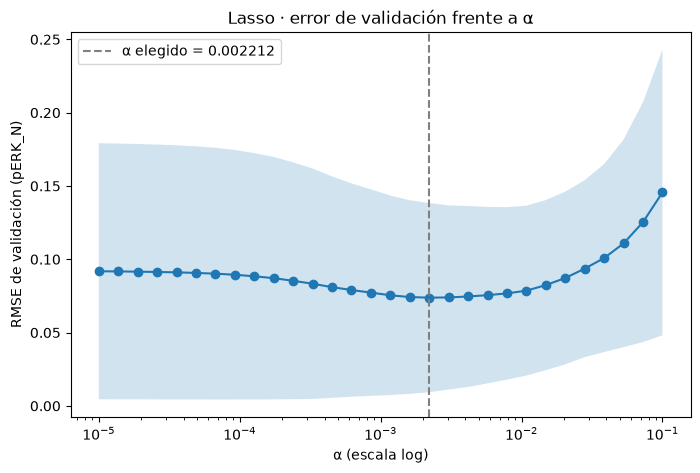

In [24]:
busqueda_lasso = buscar_hiperparametros(
    Lasso(max_iter=50_000), {"regressor__modelo__alpha": np.logspace(-5, -1, 30)},
    "Lasso", "lasso_alpha.png")

> **Interpretación:** Lasso muestra la misma forma de U, pero desplazada hacia valores de α mucho menores: el RMSE
> baja de 0,092 con α = 0,00001 a un mínimo de 0,0738 con α ≈ 0,0022 y sube hasta 0,146 con α = 0,1. Esto se debe
> a que la penalización L1 no solo reduce los coeficientes, sino que los lleva exactamente a cero, de modo que con
> α algo mayores elimina casi todos los predictores; por esa razón, la grilla de Lasso se definió entre 0,00001 y
> 0,1, y el α elegido también queda en su interior.

Elastic Net · alpha = 0.01438, l1_ratio = 0.1 | RMSE de validación: 0.0732 ± 0.0644


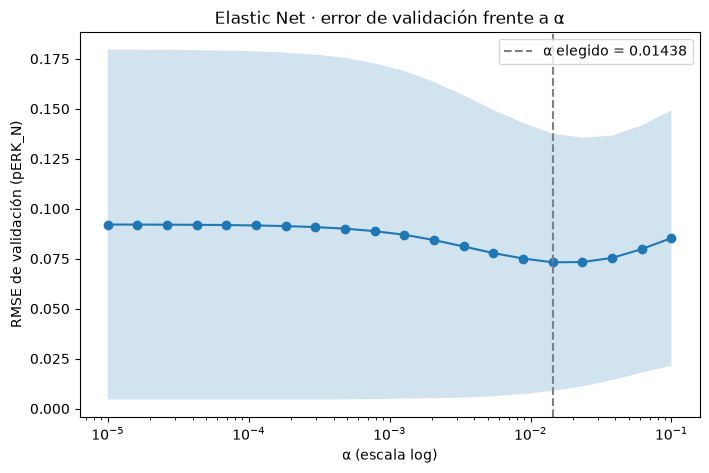

In [25]:
busqueda_enet = buscar_hiperparametros(
    ElasticNet(max_iter=50_000),
    {"regressor__modelo__alpha": np.logspace(-5, -1, 20),
     "regressor__modelo__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    "Elastic Net", "enet_alpha.png")

> **Interpretación:** Elastic Net elige `l1_ratio` = 0,1, es decir, una penalización formada en un 90 % por la de
> Ridge, con α ≈ 0,014. Esta elección es coherente con la estructura de los datos: cuando los predictores forman
> bloques muy correlacionados, la penalización tipo Ridge reparte el peso entre ellos en lugar de quedarse con uno
> solo, como tiende a hacer Lasso (Zou & Hastie, 2005).
>
> En conjunto, los tres modelos alcanzan un RMSE de validación muy similar, alrededor de 0,074 (Ridge: 0,0748;
> Lasso: 0,0738; Elastic Net: 0,0732). Cabe aclarar que el valor que acompaña a cada RMSE no es un intervalo de
> confianza, sino la desviación estándar del RMSE entre los 5 pliegues. En ese sentido, las diferencias entre
> modelos son de apenas 0,001, mientras que la variación entre pliegues es de unas 0,06, es decir, cerca de 60 veces
> mayor; por tanto, se trata de un empate estadístico y ningún modelo puede considerarse mejor que los otros con
> estos datos. Además, esa diferencia no es grande en términos prácticos: como
> `TransformedTargetRegressor` devuelve las predicciones en la escala original, 0,001 unidades de `pERK_N`
> equivalen a cerca del 0,2 % de su nivel medio (≈ 0,55). En cambio, frente a la línea base (RMSE = 0,315), los
> tres modelos reducen el error en cerca de un 76 %. Por último, la desviación entre pliegues es grande porque el
> pliegue que contiene al ratón 3484 concentra errores mucho mayores que el resto, como ya ocurría con la línea base.

### 5.2 Proteínas que conserva Lasso

In [26]:
# Coeficientes del mejor Lasso, en desviaciones estándar de log(proteína)
mejor_lasso = busqueda_lasso.best_estimator_.regressor_
coef_lasso = pd.Series(mejor_lasso.named_steps["modelo"].coef_,
                       index=mejor_lasso.named_steps["prep"].get_feature_names_out())
seleccionadas = coef_lasso[coef_lasso != 0].sort_values(key=abs, ascending=False)

print(f"Lasso conserva {len(seleccionadas)} de {len(coef_lasso)} predictores")
seleccionadas.round(3).head(15)

Lasso conserva 39 de 78 predictores


BRAF_N             0.165
DYRK1A_N           0.160
Behavior_S/C      -0.085
pNR2A_N            0.084
SOD1_N            -0.062
ITSN1_N            0.032
NR1_N             -0.031
pP70S6_N          -0.031
pPKCG_N           -0.030
Genotype_Ts65Dn   -0.026
nNOS_N             0.024
Ubiquitin_N       -0.024
H3AcK18_N         -0.014
GluR4_N            0.013
pGSK3B_Tyr216_N    0.013
dtype: float64

> **Interpretación:** Lasso conserva 39 de los 78 predictores y anula el resto. Sus coeficientes están en
> desviaciones estándar del logaritmo de cada proteína, de modo que se pueden comparar entre sí: por ejemplo, un
> aumento de una desviación estándar en `log(BRAF_N)` se asocia con un aumento de 0,165 en `log(pERK_N)`, con lo
> demás constante. En primer lugar, los dos predictores con mayor peso son `BRAF_N` (0,165) y `DYRK1A_N` (0,160),
> los mismos que resultaron significativos en M1; es decir, al disponer de las 75 proteínas, el modelo vuelve a
> elegir las que se propusieron por razones biológicas en la sección 1. En segundo lugar, `ITSN1_N` se conserva pero
> con un coeficiente pequeño (0,032), lo que es coherente con su colinealidad con `DYRK1A_N` (sección 4.3).
> Asimismo, entre las variables de diseño, la conducta tiene el mayor efecto (`Behavior_S/C` = −0,085) y el genotipo
> uno menor (−0,026), mientras que el tratamiento queda en cero, en concordancia con su falta de significancia en
> M1. Por otra parte, `pMEK_N` y `ERK_N` también quedan en cero, tal como anticipaba su baja correlación con
> `pERK_N` en la Actividad 1. No obstante, cuando varios predictores están muy correlacionados, Lasso tiende a
> quedarse con uno de ellos de forma algo arbitraria, por lo que la estabilidad de esta selección se evalúa entre
> pliegues en la sección 7 antes de interpretar las proteínas de menor peso, como `pNR2A_N` o `SOD1_N`.

## 6. Validación cruzada y comparación

¿Qué modelo predice mejor `pERK_N` en ratones que no vio durante el ajuste? Todos los modelos se evalúan con los
mismos 5 pliegues agrupados por ratón (`cv`) y con las cuatro métricas del enunciado: R², MSE, RMSE y MAE, en la
escala original de `pERK_N`. Se reporta la media y la desviación estándar entre pliegues, junto con la línea base.

### 6.1 M1 y M2-MCO como pipelines

Ridge, Lasso y Elastic Net ya están definidos por sus búsquedas de la sección 5. Faltan M1 en log-log, con las
mismas variables y escala de la sección 4.7, y M2 sin penalizar (MCO), que sirve de referencia para medir lo que
aporta la regularización. Ambos usan `TransformedTargetRegressor`, de modo que todas las métricas quedan en la escala
original de `pERK_N`.

In [27]:
# M1 en log-log: log de las tres proteínas, una columna 0/1 por variable de diseño
prep_m1 = ColumnTransformer([
    ("num", FunctionTransformer(np.log, feature_names_out="one-to-one"), PREDICTORES_M1),
    ("cat", OneHotEncoder(drop="if_binary"), DISENO),
], verbose_feature_names_out=False)

m1_sklearn = TransformedTargetRegressor(
    regressor=Pipeline([("prep", prep_m1), ("modelo", LinearRegression())]),
    func=np.log, inverse_func=np.exp)

# M2 sin penalizar: referencia para medir lo que aporta la regularización
m2_mco = TransformedTargetRegressor(
    regressor=Pipeline([("prep", prep), ("modelo", LinearRegression())]),
    func=np.log, inverse_func=np.exp)

X_train_m1 = train[PREDICTORES_M1 + DISENO]

In [28]:
# Verificación: M1 en sklearn reproduce los coeficientes de M1 log-log en statsmodels (sección 4.5)
m1_sklearn.fit(X_train_m1, y_train)
coef_sklearn = m1_sklearn.regressor_.named_steps["modelo"].coef_
coef_statsmodels = m1_log.params[[f"np.log({p})" for p in PREDICTORES_M1]
                                 + ["C(Genotype)[T.Ts65Dn]", "C(Treatment)[T.Saline]", "C(Behavior)[T.S/C]"]]
assert np.allclose(coef_sklearn, coef_statsmodels)
print("Coeficientes de M1 idénticos en sklearn y statsmodels")

Coeficientes de M1 idénticos en sklearn y statsmodels


### 6.2 Comparación de los seis modelos

¿Qué modelos superan a la línea base, cuál generaliza mejor y qué aporta la regularización frente a MCO?

In [29]:
modelos = {
    "Línea base": (DummyRegressor(strategy="mean"), X_train),
    "M1 log-log": (m1_sklearn, X_train_m1),
    "M2 MCO": (m2_mco, X_train),
    "M2 Ridge": (busqueda_ridge.best_estimator_, X_train),
    "M2 Lasso": (busqueda_lasso.best_estimator_, X_train),
    "M2 Elastic Net": (busqueda_enet.best_estimator_, X_train),
}

def evaluar(modelo, X):
    """Validación cruzada agrupada por ratón: métricas de validación por pliegue y RMSE de entrenamiento."""
    r = cross_validate(modelo, X, y_train, groups=grupos_train, cv=cv,
                       scoring=METRICAS, return_train_score=True)
    validacion = pd.DataFrame({m: r[f"test_{m}"] if m == "R2" else -r[f"test_{m}"] for m in METRICAS})
    return validacion, -r["train_RMSE"]

resultados = {nombre: evaluar(modelo, X) for nombre, (modelo, X) in modelos.items()}

# Tabla: media ± DE de cada métrica, más el RMSE de entrenamiento
tabla_cv = pd.DataFrame({
    nombre: {
        **{m: f"{val[m].mean():.3f} ± {val[m].std():.3f}" for m in METRICAS},
        "RMSE entrenamiento": f"{entr.mean():.3f}",
    }
    for nombre, (val, entr) in resultados.items()
}).T
tabla_cv

,R2,MSE,RMSE,MAE,RMSE entrenamiento
Línea base,-0.373 ± 0.728,0.132 ± 0.182,0.315 ± 0.204,0.226 ± 0.086,0.353
M1 log-log,0.869 ± 0.068,0.012 ± 0.015,0.095 ± 0.057,0.055 ± 0.011,0.102
M2 MCO,0.914 ± 0.054,0.016 ± 0.031,0.092 ± 0.098,0.044 ± 0.017,0.079
M2 Ridge,0.939 ± 0.027,0.009 ± 0.017,0.075 ± 0.069,0.041 ± 0.019,0.082
M2 Lasso,0.944 ± 0.026,0.010 ± 0.017,0.074 ± 0.072,0.038 ± 0.016,0.082
M2 Elastic Net,0.945 ± 0.027,0.009 ± 0.017,0.073 ± 0.072,0.038 ± 0.016,0.082


> **Interpretación:** Todos los modelos superan ampliamente a la línea base, ya que su RMSE de validación (0,315)
> se reduce a entre 0,073 y 0,095. Entre ellos, los tres modelos regularizados de M2 obtienen el mejor desempeño, y
> prácticamente idéntico: Elastic Net alcanza el R² más alto (0,945 ± 0,027), lo que indica que, en promedio,
> explica el 94,5 % de la variación de `pERK_N` en ratones que no vio durante el ajuste, seguido muy de cerca por
> Lasso (0,944) y Ridge (0,939). En cuanto al MSE, al elevar los errores al cuadrado pesa todavía más el pliegue
> que contiene al ratón 3484; por eso M2 MCO, cuyo error se dispara en ese pliegue, tiene un MSE mayor que M1
> (0,016 frente a 0,012) aunque su RMSE medio sea algo menor.
>
> Por otra parte, M2 MCO obtiene el menor RMSE de entrenamiento (0,079), pero no el menor de validación
> (0,092 ± 0,098), que además es el más variable de todos. Esta combinación es la señal del sobreajuste: sin
> penalización, el modelo con 78 predictores se adapta mejor a los ratones con que se entrena, pero generaliza peor
> y de forma más inestable. En consecuencia, el aporte de la regularización no es reducir el error de
> entrenamiento, que de hecho sube levemente (de 0,079 a 0,082), sino reducir el error de validación de 0,092 a
> cerca de 0,074 y su desviación estándar de 0,098 a cerca de 0,07; es decir, sacrifica un poco de ajuste a cambio
> de predecir mejor ratones nuevos (James et al., 2023).
>
> En cuanto a M1 log-log, con solo tres proteínas y las variables de diseño explica el 86,9 % de la variación de
> `pERK_N`, aunque tiene el mayor error entre los modelos (RMSE = 0,095; MAE = 0,055). Frente a M2 regularizado, su
> MAE es cerca de un 30 % mayor (0,055 frente a 0,038). Cabe señalar que el valor después de cada ± es la
> desviación estándar (DE) de la métrica entre los 5 pliegues; como la diferencia de RMSE entre M1 y M2 (≈ 0,02) es
> menor que esa DE (≈ 0,06–0,07), la tabla por sí sola no basta para afirmar que M2 sea mejor, y la comparación se
> completa pliegue a pliegue en la sección 6.3.

### 6.3 RMSE por pliegue

¿Las diferencias entre modelos se mantienen en todos los pliegues o dependen de uno solo? Como todos los modelos se
evalúan sobre los mismos pliegues, cada línea del gráfico une el RMSE de los seis modelos en un mismo pliegue.

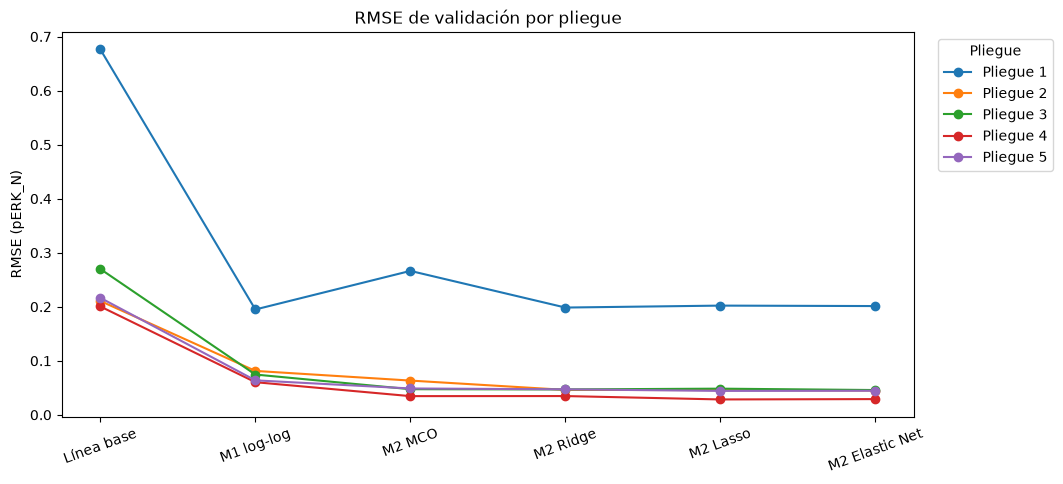

,Línea base,M1 log-log,M2 MCO,M2 Ridge,M2 Lasso,M2 Elastic Net
Pliegue 1,0.676,0.195,0.266,0.199,0.202,0.201
Pliegue 2,0.211,0.081,0.063,0.046,0.046,0.045
Pliegue 3,0.270,0.075,0.047,0.047,0.048,0.046
Pliegue 4,0.201,0.060,0.035,0.035,0.028,0.029
Pliegue 5,0.217,0.064,0.049,0.047,0.044,0.045


In [30]:
rmse_pliegues = pd.DataFrame({nombre: val["RMSE"] for nombre, (val, _) in resultados.items()})
rmse_pliegues.index = [f"Pliegue {i + 1}" for i in range(len(rmse_pliegues))]

fig, ax = plt.subplots(figsize=(11, 5))
for pliegue, fila in rmse_pliegues.iterrows():
    ax.plot(fila.index, fila.values, marker="o", label=pliegue)
ax.set(title="RMSE de validación por pliegue", ylabel="RMSE (pERK_N)", xlabel="")
ax.legend(title="Pliegue", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=20)
plt.savefig(FIGURAS / "comparacion_rmse_pliegues.png", dpi=150, bbox_inches="tight")
plt.show()

rmse_pliegues.round(3)

> **Interpretación:** En los pliegues 2 a 5, los tres modelos regularizados de M2 tienen un RMSE menor que M1 en
> todos los casos (entre 0,028 y 0,048, frente a entre 0,060 y 0,081), de modo que su ventaja es consistente y no
> depende de un pliegue en particular. Esto sugiere que M2 aprovecha información de otras proteínas que M1 no
> incluye, como `pNR2A_N` o `SOD1_N` (sección 5.2). La excepción es el pliegue 1, que contiene al ratón 3484: todos
> los modelos alcanzan ahí su mayor error (cerca de 0,20), y M1 resulta incluso ligeramente mejor (0,195 frente a
> 0,199–0,202), mientras que M2 MCO llega a 0,266. Es decir, ante un ratón con valores extremos, los modelos con
> pocos predictores o penalizados se desvían menos que uno con 78 predictores sin penalizar, y es en ese pliegue
> donde la regularización marca la mayor diferencia frente a MCO.
>
> En conjunto, M2 regularizado predice mejor que M1, aunque la ventaja es moderada, y la regularización sí aporta
> frente a MCO. En cambio, las líneas de Ridge, Lasso y Elastic Net prácticamente se superponen en los cinco
> pliegues, lo que confirma el empate estadístico entre ellos observado en la sección 5.

## 7. Estabilidad de coeficientes, modelo final y prueba

Las secciones 5 y 6 mostraron un empate en desempeño entre Ridge, Lasso y Elastic Net; por tanto, la elección del
modelo final se apoya también en la estabilidad de sus coeficientes y en su interpretabilidad. Este criterio sigue
la lógica de la regla de una desviación estándar: cuando varios modelos tienen errores equivalentes, se prefiere
el más simple o estable (James et al., 2023). La estabilidad se mide reajustando cada modelo en los 5 pliegues de
entrenamiento y comparando sus coeficientes entre pliegues.

In [31]:
def coeficientes_por_pliegue(modelo, X):
    """Coeficientes del modelo ajustado en cada pliegue de entrenamiento (una fila por pliegue)."""
    r = cross_validate(modelo, X, y_train, groups=grupos_train, cv=cv, return_estimator=True)
    return pd.DataFrame([
        pd.Series(est.regressor_.named_steps["modelo"].coef_,
                  index=est.regressor_.named_steps["prep"].get_feature_names_out())
        for est in r["estimator"]
    ])

### 7.1 Estabilidad de M1

¿Los coeficientes de M1 log-log cambian de magnitud o de signo según los ratones que quedan en el entrenamiento?

In [32]:
coef_m1 = coeficientes_por_pliegue(m1_sklearn, X_train_m1)

estabilidad_m1 = pd.DataFrame({
    "media": coef_m1.mean(),
    "de": coef_m1.std(),
    "mínimo": coef_m1.min(),
    "máximo": coef_m1.max(),
    "pliegues con otro signo": (np.sign(coef_m1) != np.sign(coef_m1.mean())).sum(),
}).round(3)
estabilidad_m1

,media,de,mínimo,máximo,pliegues con otro signo
DYRK1A_N,0.548,0.064,0.447,0.600,0
BRAF_N,0.199,0.060,0.142,0.285,0
ITSN1_N,0.234,0.092,0.083,0.331,0
Genotype_Ts65Dn,-0.113,0.019,-0.135,-0.086,0
Treatment_Saline,-0.045,0.009,-0.054,-0.031,0
Behavior_S/C,-0.213,0.027,-0.246,-0.174,0


> **Interpretación:** Ningún coeficiente de M1 cambia de signo entre pliegues, y sus magnitudes varían poco: por
> ejemplo, la elasticidad de `DYRK1A_N` va de 0,45 a 0,60 (media 0,55) y el efecto de la conducta, de −0,25 a −0,17.
> El coeficiente menos estable es el de `ITSN1_N` (de 0,08 a 0,33), lo que es coherente con su colinealidad con
> `DYRK1A_N` (sección 4.3) y con su falta de significancia en la sección 4.7. En consecuencia, en escala log-log las
> conclusiones de M1 no dependen de qué ratones quedan en el entrenamiento, lo que respalda su uso para interpretar.

### 7.2 Estabilidad de los modelos regularizados

¿Las proteínas que conserva cada modelo y el peso de los predictores de M1 se mantienen entre pliegues? Para Lasso y
Elastic Net se cuenta en cuántos pliegues cada coeficiente es distinto de 0; para los tres modelos se calcula la
variación relativa (DE / |media|) de los coeficientes de M1, donde valores bajos indican estabilidad.

In [33]:
regularizados = {"Ridge": busqueda_ridge, "Lasso": busqueda_lasso, "Elastic Net": busqueda_enet}
coef_m2 = {nombre: coeficientes_por_pliegue(b.best_estimator_, X_train) for nombre, b in regularizados.items()}

# Frecuencia de selección de los 78 predictores en los 5 pliegues
seleccion = pd.DataFrame({
    nombre: {
        "En los 5 pliegues": (c != 0).all().sum(),
        "Solo en algunos": ((c != 0).any() & ~(c != 0).all()).sum(),
        "En ningún pliegue": (c == 0).all().sum(),
    }
    for nombre, c in coef_m2.items()
})

# Variación relativa de los coeficientes de los predictores de M1 en cada modelo
clave = PREDICTORES_M1 + ["Genotype_Ts65Dn", "Behavior_S/C"]
variacion = pd.DataFrame({nombre: c[clave].std() / c[clave].mean().abs() for nombre, c in coef_m2.items()}).round(2)

display(seleccion)
variacion

,Ridge,Lasso,Elastic Net
En los 5 pliegues,78,21,32
Solo en algunos,0,35,32
En ningún pliegue,0,22,14


,Ridge,Lasso,Elastic Net
DYRK1A_N,0.13,0.24,0.18
BRAF_N,0.06,0.18,0.13
ITSN1_N,0.09,0.91,0.26
Genotype_Ts65Dn,0.27,0.38,0.25
Behavior_S/C,0.13,0.36,0.18


> **Interpretación:** Los tres modelos difieren en estabilidad, aunque no en desempeño. Ridge conserva siempre los 78
> predictores y tiene los coeficientes más estables (variación relativa entre 0,06 y 0,27), pero no selecciona
> variables. Lasso, en cambio, solo conserva 21 predictores en los 5 pliegues, y 35 entran o salen según el pliegue;
> además, el coeficiente de `ITSN1_N` varía casi tanto como su propia magnitud (0,91), ya que Lasso tiende a quedarse
> con una de las proteínas colineales y la elección cambia entre pliegues. Elastic Net ocupa un punto intermedio:
> conserva 32 predictores en los 5 pliegues, descarta 14 en todos ellos y mantiene estables los coeficientes de M1
> (entre 0,13 y 0,26), incluido `ITSN1_N`, porque su componente de Ridge reparte el peso entre proteínas
> correlacionadas en lugar de elegir una (Zou & Hastie, 2005). Por tanto, la selección de proteínas de Lasso
> (sección 5.2) debe leerse con cautela en las de menor peso, mientras que la de Elastic Net es más reproducible.

### 7.3 Elección del modelo final

| Criterio | M1 log-log | M2 MCO | M2 Ridge | M2 Lasso | M2 Elastic Net |
|---|---|---|---|---|---|
| RMSE de validación | 0,095 ± 0,057 | 0,092 ± 0,098 | 0,075 ± 0,069 | 0,074 ± 0,072 | 0,073 ± 0,072 |
| Sobreajuste | Bajo | Alto (pliegue 1: 0,266) | Bajo | Bajo | Bajo |
| Estabilidad de coeficientes | Alta, sin cambios de signo | Baja (colinealidad) | La más alta | Baja en proteínas colineales | Alta |
| Selección de variables | 3 proteínas fijas | No | No (78 predictores) | Sí, poco estable | Sí, estable (32 en los 5 pliegues) |
| Interpretación | Elasticidades con IC por ratón | No fiable | Difícil con 78 predictores | Parcial | Parcial |

En consecuencia, se eligen dos modelos con propósitos distintos. Para **predecir**, el modelo final es M2 Elastic
Net, ya que comparte el mejor desempeño con Ridge y Lasso, pero combina la estabilidad de Ridge con una selección
de proteínas reproducible. Para **explicar**, se conserva M1 log-log, porque sus coeficientes son estables, tienen
intervalos de confianza agrupados por ratón y se leen directamente como elasticidades y diferencias porcentuales,
aunque su error es algo mayor. Ambos se evalúan una sola vez en el conjunto de prueba, junto con la línea base como
referencia.

### 7.4 Evaluación en el conjunto de prueba

¿El desempeño en los 14 ratones de prueba, que no se usaron en ninguna decisión anterior, confirma lo observado en
la validación cruzada?

In [34]:
X_test = test[PROTEINAS_M2 + DISENO]
y_test = test[OBJETIVO]

# Modelos finales ajustados con todo el entrenamiento; la línea base predice la media del entrenamiento
predicciones = {
    "Línea base": np.full(len(y_test), y_train.mean()),
    "M1 log-log": m1_sklearn.fit(X_train_m1, y_train).predict(test[PREDICTORES_M1 + DISENO]),
    "M2 Elastic Net": busqueda_enet.best_estimator_.predict(X_test),
}

tabla_prueba = pd.DataFrame({
    nombre: {
        "R2": r2_score(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
    }
    for nombre, pred in predicciones.items()
}).T.round(3)
tabla_prueba

,R2,MSE,RMSE,MAE
Línea base,-0.004,0.075,0.273,0.223
M1 log-log,0.919,0.006,0.078,0.050
M2 Elastic Net,0.972,0.002,0.046,0.033


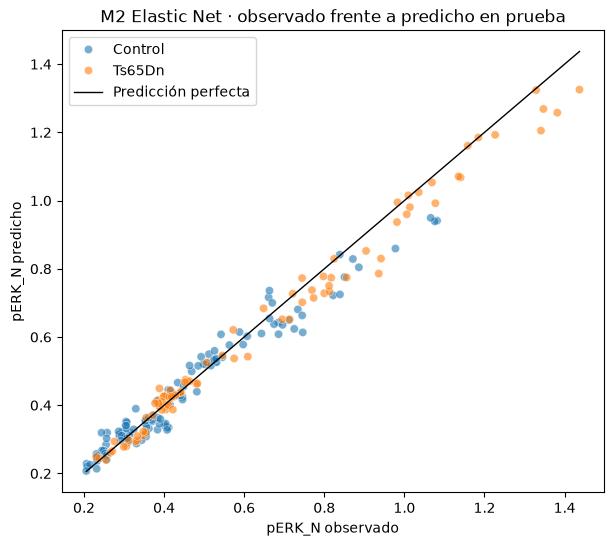

raton
311     0.082
363     0.060
3498    0.050
dtype: float64

In [35]:
pred_enet = pd.Series(predicciones["M2 Elastic Net"], index=y_test.index)

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(x=y_test, y=pred_enet, hue=test["Genotype"], alpha=0.6, ax=ax)
limites = [min(y_test.min(), pred_enet.min()), max(y_test.max(), pred_enet.max())]
ax.plot(limites, limites, color="black", linewidth=1, label="Predicción perfecta")
ax.set(title="M2 Elastic Net · observado frente a predicho en prueba",
       xlabel="pERK_N observado", ylabel="pERK_N predicho")
ax.legend()
plt.savefig(FIGURAS / "enet_prueba.png", dpi=150, bbox_inches="tight")
plt.show()

# Ratones de prueba con mayor error absoluto medio
(y_test - pred_enet).abs().groupby(test[GRUPO]).mean().sort_values(ascending=False).head(3).round(3)

> **Interpretación:** En el conjunto de prueba, M2 Elastic Net alcanza un R² de 0,97, con RMSE = 0,046 y
> MAE = 0,033, frente a un RMSE de 0,273 de la línea base; es decir, reduce el error en cerca de un 83 %. M1 log-log
> también predice bien (R² = 0,92; RMSE = 0,078; MAE = 0,050), aunque con un error mayor, lo que confirma el orden
> observado en la validación cruzada. Además, en el gráfico los puntos se ubican cerca de la diagonal para ambos
> genotipos; sin embargo, por encima de un `pERK_N` observado de 0,8 el modelo tiende a subestimar levemente, lo que
> es esperable en un modelo penalizado, ya que la regularización encoge las predicciones hacia la media (James et
> al., 2023).
>
> Cabe señalar que el RMSE de prueba (0,046) es menor que el promedio de la validación cruzada (0,073). Esto no
> indica fuga de información, sino que el conjunto de prueba no contiene ratones extremos: el 3484 quedó en el
> entrenamiento, y el `pERK_N` de prueba va de 0,21 a 1,44. De hecho, el error de prueba coincide con el de los
> pliegues de validación sin ese ratón (entre 0,029 y 0,046). Por tanto, el modelo predice con precisión ratones
> dentro del rango habitual, pero su desempeño ante un individuo extremo como el 3484 es incierto, ya que en el
> pliegue que lo contenía el RMSE llegó a cerca de 0,20.

## 8. Conclusiones y limitaciones

### 8.1 Conclusiones

1. **El nivel de `pERK_N` se explica en gran medida por unas pocas proteínas y por la condición experimental.** En
   M1 log-log, un 1 % más de `DYRK1A_N` se asocia con un 0,55 % más de `pERK_N`, y un 1 % más de `BRAF_N`, con un
   0,20 % más, manteniendo constante lo demás. Además, con los mismos niveles de estas proteínas, los ratones Ts65Dn
   tienen cerca de un 11 % menos de `pERK_N` que los controles, y los no estimulados para aprender, cerca de un 19 %
   menos que los estimulados, lo que es coherente con la activación de ERK durante el aprendizaje (Sweatt, 2004). En
   cambio, no hay evidencia de un efecto de la memantina, y el aporte propio de `ITSN1_N` no se distingue del de
   `DYRK1A_N` por su colinealidad.
2. **Reconocer la estructura de los datos cambia las conclusiones.** Al agrupar los errores estándar por ratón, el
   tratamiento dejó de ser significativo: con MCO ordinario se habría concluido que la memantina se asocia con
   `pERK_N`, cuando era un artefacto de tratar 15 réplicas como 15 individuos (Cameron & Miller, 2015).
3. **La escala log-log hizo el modelo robusto a un solo ratón.** En escala original, el ratón 3484 cambiaba qué
   proteína parecía importar; en log-log, los coeficientes se mantienen con o sin él y entre pliegues.
4. **La regularización mejora la predicción frente a MCO, pero Ridge, Lasso y Elastic Net empatan entre sí.** Frente
   a M2 sin penalizar, reduce el RMSE de validación de 0,092 a cerca de 0,074 y su variación entre pliegues, sobre
   todo en el pliegue más difícil. El modelo final para predecir es M2 Elastic Net, por combinar ese desempeño con
   coeficientes estables (Zou & Hastie, 2005); en el conjunto de prueba alcanza R² = 0,97 y RMSE = 0,046, un 83 %
   menos de error que la línea base.
5. **Los resultados predictivos e interpretativos coinciden.** Al disponer de las 75 proteínas, los modelos
   regularizados vuelven a dar el mayor peso a `BRAF_N` y `DYRK1A_N`, las mismas elegidas por razones biológicas en
   la sección 1 (Kelly & Rahmani, 2005).

### 8.2 Limitaciones

- **Tamaño efectivo pequeño.** Aunque hay 1.077 filas, el análisis descansa en 72 ratones: 58 de entrenamiento y
  14 de prueba. Por eso las métricas varían mucho entre pliegues y las diferencias pequeñas entre modelos no se
  pueden distinguir.
- **El conjunto de prueba no incluye ratones extremos.** El ratón 3484 quedó en el entrenamiento, de modo que el
  error de prueba (RMSE = 0,046) describe ratones dentro del rango habitual; ante un individuo como ese, el error
  observado en validación fue cercano a 0,20.
- **Asociaciones, no efectos causales.** Las proteínas se miden al mismo tiempo que `pERK_N`, así que los
  coeficientes describen cómo co-varían dentro de este diseño experimental y no qué ocurriría al modificar una de
  ellas. Tampoco son válidos fuera del rango observado.
- **Supuestos cumplidos solo en parte.** Incluso en log-log, los residuos tienen colas pesadas y dependen del ratón;
  la inferencia se protege con errores estándar agrupados y la validación con `GroupKFold` (Roberts et al., 2017),
  pero los intervalos con 58 ratones son aproximados.
- **Ligero optimismo en la comparación.** El α de cada modelo regularizado se eligió con los mismos pliegues con que
  luego se compararon los modelos; una validación cruzada anidada daría una estimación más conservadora (Kuhn &
  Johnson, 2019), aunque el
  resultado en prueba, que no intervino en ninguna decisión, confirma el desempeño.
- **Imputación de proteínas ausentes en bloque.** En M2, ocho proteínas faltan por completo en algunos ratones y se
  imputan con k vecinos más cercanos a partir de ratones con perfil similar, según la decisión de la Actividad 1;
  sus coeficientes son, por tanto, menos
  fiables que los de proteínas medidas en todos los ratones.

### 8.3 Implicaciones para la Actividad 3

La clasificación de las 8 clases debe mantener la partición y la validación agrupadas por ratón, aplicar el
logaritmo y la imputación dentro del `Pipeline` y tener en cuenta la colinealidad entre proteínas. Además, que la
conducta y el genotipo desplacen el nivel de `pERK_N` aun con las mismas proteínas sugiere que estas variables
contienen información útil para distinguir las condiciones experimentales.

## Referencias

Breusch, T. S., & Pagan, A. R. (1979). A simple test for heteroscedasticity and random coefficient variation. *Econometrica, 47*(5), 1287–1294. https://doi.org/10.2307/1911963

Cameron, A. C., & Miller, D. L. (2015). A practitioner’s guide to cluster-robust inference. *Journal of Human Resources, 50*(2), 317–372. https://doi.org/10.3368/jhr.50.2.317

Cook, R. D. (1977). Detection of influential observation in linear regression. *Technometrics, 19*(1), 15–18. https://doi.org/10.1080/00401706.1977.10489493

Durbin, J., & Watson, G. S. (1950). Testing for serial correlation in least squares regression: I. *Biometrika, 37*(3–4), 409–428.

Higuera, C., Gardiner, K. J., & Cios, K. J. (2015). Self-organizing feature maps identify proteins critical to learning in a mouse model of Down syndrome. *PLOS ONE, 10*(6), e0129126. https://doi.org/10.1371/journal.pone.0129126

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0

Jarque, C. M., & Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2), 163–172. https://doi.org/10.2307/1403192

Kelly, P. A., & Rahmani, Z. (2005). DYRK1A enhances the mitogen-activated protein kinase cascade in PC12 cells by forming a complex with Ras, B-Raf, and MEK1. *Molecular Biology of the Cell, 16*(8), 3562–3573. https://doi.org/10.1091/mbc.e04-12-1085

Kuhn, M., & Johnson, K. (2019). *Feature engineering and selection: A practical approach for predictive models*. CRC Press.

Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., Hauenstein, S., Lahoz-Monfort, J. J., Schröder, B., Thuiller, W., Warton, D. I., Wintle, B. A., Hartig, F., & Dormann, C. F. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography, 40*(8), 913–929. https://doi.org/10.1111/ecog.02881

Sweatt, J. D. (2004). Mitogen-activated protein kinases in synaptic plasticity and memory. *Current Opinion in Neurobiology, 14*(3), 311–317. https://doi.org/10.1016/j.conb.2004.04.001

Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B, 67*(2), 301–320. https://doi.org/10.1111/j.1467-9868.2005.00503.x